# Extensões: placebo, few-shot por analogia e reescrita estruturada

Este notebook **não altera nada** do `analise_jev.ipynb` nem refaz o que já rodou: só lê os resultados e caches
que já existem e grava os seus próprios arquivos (nomes novos).

**Parte 1: o cartão ajuda por informação ou só por "ter contexto"? E estimar por analogia ajuda?**
Lê as predições do `30_run_llm.py` (nenhuma chamada de LLM aqui) e compara, nas mesmas issues:
- `ZS1` × `ZS1 + cartão` × `ZS1 + placebo` (cartão de **outro** projeto do mesmo dataset). Se o cartão real não
  ganhar do placebo, o ganho do cartão é calibração genérica, não informação do projeto.
- few-shot com exemplos do treino do **mesmo projeto**: sorteados × **os mais parecidos** (TF-IDF), com e sem
  cartão. É o que um time faz ao estimar por analogia; a mediana do projeto é a referência a vencer.

**Parte 2: reescrita estruturada pelos fatores de esforço** (motivação: Rasheed et al., 2026, *Automated Software
Engineering* 33:60, mostram que tamanho, complexidade, tecnologias, linguagem e plataforma são os fatores que mais
explicam o esforço, e deixam como trabalho futuro extraí-los do texto com LLM).
- Nova versão do texto, **estruturar_contexto**: o LLM reescreve a issue num modelo fixo (tipo, objetivo, escopo,
  componentes afetados, tecnologias, dependências externas, critérios de aceite, dúvidas em aberto), usando só a
  issue e o cartão do projeto, e escreve **"Not stated"** quando a informação não existe. Tamanho e complexidade
  ficam de fora de propósito: seria o LLM estimando disfarçado.
- Entra no fatorial da seção 12 como 5ª versão (× cartão sim/não no estimador), nas mesmas issues.
- **Lacunas:** quantos campos ficaram "Not stated" mede o que falta nas issues reais, e se isso se relaciona com o
  erro.

**Ordem para rodar** (os comandos do `30_run_llm.py` podem rodar enquanto você faz outra coisa; não rode dois
processos no mesmo Ollama ao mesmo tempo, fica lento para os dois):
1. `analise_jev.ipynb` até a seção 12 (a parte 2 usa os caches dela).
2. Os comandos da parte 1 (célula de configuração abaixo).
3. Este notebook, de cima a baixo. Cada parte pula sozinha o que ainda não tiver os arquivos.

In [1]:
# ============================== CONFIGURAÇÃO ==============================
DATASETS = ["agile_limpo", "neo_limpo"]
LLM = "llama3"                     # nome do modelo usado no 30_run_llm.py (prefixo dos arquivos de predição)
ENGINE = "jev"; SUBSET = "test"     # os mesmos do analise_jev.ipynb

# Parte 2 (os mesmos do analise_jev.ipynb)
REWRITER = {"provider": "ollama", "model": "llama3"}   # quem faz a reescrita estruturada
#   Para testar se o problema é o modelo, troque SÓ o reescritor, ex.: {"provider": "gemini", "model": "gemini-2.5-flash"}
#   (defina GEMINI_API_KEY; ~135 chamadas). O estimador continua o mesmo, e a versão do llama3 entra na
#   comparação ao lado da nova (os caches do llama3 não são apagados nem misturados).
REWRITER_RPM = 0                   # Gemini gratuito: use 10
ESTIMADOR_LLM = {"provider": "ollama", "model": "llama3"}
ESTIMADORES_ML = ["KNN", "XGBoost"]
RODAR_PARTE_2 = True               # False = só a parte 1 (não chama LLM nem Jev)
RETENTAR_FALHAS = False            # True = tenta de novo as reescritas que falharam (muda o conjunto de issues)
RODAR_REESCRITA_X_ANALOGIA = True  # seção 2g: cada versão do texto estimada por analogia (~660 chamadas, ~1,5 h no llama3)

# Chaves de API: se faltarem, o notebook pergunta na hora (campo de senha, não fica salvo no arquivo).
# NÃO escreva a chave do Jev aqui.

# ---- Comandos da parte 1 (rode no terminal, da pasta do repositório) ----
# 1) placebo (≈ 787 chamadas):
#    python repro/30_run_llm.py --provider ollama --model llama3 --dataset agile_limpo neo_limpo --cartao-placebo
# 2) few-shot com os exemplos mais parecidos do mesmo projeto (≈ 787):
#    python repro/30_run_llm.py --provider ollama --model llama3 --dataset agile_limpo neo_limpo --protocol within --template FS1 --shots-from similar_same_project --so-projetos-com-cartao
# 3) o mesmo + cartão (≈ 787):
#    python repro/30_run_llm.py --provider ollama --model llama3 --dataset agile_limpo neo_limpo --protocol within --template FS1 --shots-from similar_same_project --cartao
# 4) controle: exemplos do mesmo projeto SORTEADOS (≈ 787):
#    python repro/30_run_llm.py --provider ollama --model llama3 --dataset agile_limpo neo_limpo --protocol within --template FS1 --shots-from same_project --so-projetos-com-cartao
# 6) LLM com a distribuição de SP do time POR TIPO de issue (seção 1f; ≈ 1.750, parte reaproveitada do --dist-sp):
#    python repro/30_run_llm.py --provider ollama --model llama3 --dataset agile_limpo neo_limpo --dist-sp --dist-sp-por tipo
# 5) opcional, few-shot com exemplos parecidos no DATASET INTEIRO (continua o arquivo do comando 2; ≈ 960 a mais):
#    python repro/30_run_llm.py --provider ollama --model llama3 --dataset agile_limpo neo_limpo --protocol within --template FS1 --shots-from similar_same_project

In [2]:
import sys, os, re, json, time, hashlib, importlib.util
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display as _ipy_display

ROOT = Path.cwd()
while not (ROOT / "see" / "config.py").exists():
    if ROOT.parent == ROOT:
        raise SystemExit("Abra o notebook de dentro da pasta repro/.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from see import config
from see.io import load_merged
from see.quality import add_quality_scores
from see.text import clean_light
from see.prompts import truncate, zero_shot, parse_estimate

EXP = config.RESULTS / "improvement"            # caches da seção 12 (lidos) e da parte 2 (nomes novos)
OUT = config.RESULTS / "analise_extensoes"       # tabelas e figuras deste notebook
FIGDIR = OUT / "figuras"
for d in (EXP, OUT, FIGDIR):
    d.mkdir(parents=True, exist_ok=True)

TABELAS, _nfig = {}, [0]
def display(obj, nome=None):
    if nome is not None and isinstance(obj, (pd.DataFrame, pd.Series)):
        TABELAS[nome] = obj.to_frame() if isinstance(obj, pd.Series) else obj.copy()
    _ipy_display(obj)

def salva_fig(nome):
    _nfig[0] += 1
    plt.gcf().savefig(FIGDIR / f"{_nfig[0]:02d}_{nome}.png", dpi=150, bbox_inches="tight")

def load_script(name):
    spec = importlib.util.spec_from_file_location(name.replace(".py", "").lstrip("0123456789_"), ROOT / name)
    mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod); return mod

def pedir_chave(var, para):
    if not os.environ.get(var):
        import getpass
        os.environ[var] = getpass.getpass(f"{var} ({para}): ").strip()
    return bool(os.environ.get(var))

def wilcoxon_pareado(a, b):
    d = (b - a).dropna()
    if len(d) < 5 or (d == 0).all():
        return {"n": len(d), "Δ média": d.mean(), "p (Wilcoxon)": np.nan, "r (rank-biserial)": np.nan}
    w = stats.wilcoxon(d)
    ranks = d.abs().rank()
    return {"n": len(d), "Δ média": d.mean(), "p (Wilcoxon)": w.pvalue,
            "r (rank-biserial)": (ranks[d > 0].sum() - ranks[d < 0].sum()) / ranks.sum()}

def bootstrap_ci(d, n=5000, seed=0):
    rng = np.random.default_rng(seed); d = np.asarray(pd.Series(d).dropna())
    if len(d) < 5:
        return (np.nan, np.nan)
    m = rng.choice(d, (n, len(d)), replace=True).mean(1)
    return tuple(np.percentile(m, [2.5, 97.5]))

def holm(p):
    # correção de Holm dentro de uma família de contrastes (NaN fica NaN)
    p = pd.Series(p, dtype=float); ok = p.dropna().sort_values()
    m = len(ok); adj = pd.Series(np.nan, index=p.index)
    run = 0.0
    for k, (i, v) in enumerate(ok.items()):
        run = max(run, min(1.0, (m - k) * v)); adj[i] = run
    return adj

TRAIN_MED = {ds: float(load_merged(ds).query("within == 'train'").sp.median()) for ds in DATASETS}
# Regra de validade (igual para TODAS as configurações): resposta fora da faixa de story points vista no treino
# (0 até o maior SP do treino) conta como inválida, como uma resposta sem número, e vira a mediana do treino.
# Pega os casos em que o parser leu outro número (ex.: o ano repetido do título) ou o LLM respondeu "500".
SP_MAX = {ds: float(load_merged(ds).query("within == 'train'").sp.max()) for ds in DATASETS}

def na_faixa(y, ds):
    y = pd.to_numeric(pd.Series(y), errors="coerce")
    ds = pd.Series(ds, index=y.index) if not isinstance(ds, str) else pd.Series(ds, index=y.index)
    return y.where((y >= 0) & (y <= ds.map(SP_MAX)))

COR = {"s1": "#2a78d6", "s2": "#eb6834", "s3": "#1baf7a", "s4": "#8a5cd6", "ink": "#0b0b0b", "ink2": "#52514e",
       "muted": "#898781", "grid": "#e1e0d9", "axis": "#c3c2b7", "surface": "#fcfcfb"}
plt.rcParams.update({
    "figure.facecolor": COR["surface"], "axes.facecolor": COR["surface"], "savefig.facecolor": COR["surface"],
    "axes.edgecolor": COR["axis"], "axes.labelcolor": COR["ink2"], "xtick.color": COR["muted"], "ytick.color": COR["muted"],
    "axes.grid": True, "grid.color": COR["grid"], "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlecolor": COR["ink"], "font.size": 9.5, "legend.frameon": False, "figure.dpi": 110,
})
pd.set_option("display.float_format", "{:.3f}".format); pd.set_option("display.width", 160)

---
# Parte 1 — Cartão × placebo e few-shot por analogia

Só lê `results/predictions/{dataset}/...` (gerados pelo `30_run_llm.py`). Todas as comparações usam **as mesmas
issues**: as do test set (`within_eval`) de projetos com cartão, presentes em todas as configurações disponíveis.
Estimativa sem número **ou fora da faixa de SP do treino** (0 até o maior SP visto no treino) → mediana do
treino, igual para todas as configurações (a primeira parte já é a regra do `90_evaluate.py`). Os p-valores têm correção de Holm dentro de
cada dataset.

In [3]:
CONFIGS = {   # nome legível -> (protocolo, arquivo)
    "ZS1":                         ("within", f"{LLM}__ZS1.csv"),
    "ZS1 + cartão":                ("within", f"{LLM}__ZS1__cartao.csv"),
    "ZS1 + placebo":               ("within", f"{LLM}__ZS1__cartaoplacebo.csv"),
    "FS mesmo projeto, sorteados": ("within_fewshot_sameproj", f"{LLM}__FS1__same_project.csv"),
    "FS mesmo projeto, parecidos": ("within_fewshot_simproj", f"{LLM}__FS1__similar_same_project.csv"),
    "FS parecidos + cartão":       ("within_fewshot_simproj", f"{LLM}__FS1__similar_same_project__cartao.csv"),
}
REFERENCIAS = {"ProjectMedian": ("within", "ProjectMedian.csv"), "SVR": ("within", "SVR.csv"),
               "XGBoost": ("within", "XGBoost.csv")}

P1, disp = {}, []
for ds in DATASETS:
    for nome, (proto, arq) in {**CONFIGS, **REFERENCIAS}.items():
        f = config.PREDICTIONS / ds / proto / arq
        ok = f.exists()
        disp.append({"dataset": ds, "configuração": nome, "arquivo": f"{proto}/{arq}", "existe": ok,
                     "issues": len(pd.read_csv(f)) if ok else 0})
        if ok:
            p = pd.read_csv(f, dtype={"issue_id": str, "project": str})
            n_test = int((load_merged(ds).within == "test").sum())
            if nome in REFERENCIAS and len(p) != n_test:      # ex.: SVR treinado no dataset errado
                print(f"⚠ {ds}/{proto}/{arq} tem {len(p)} linhas, mas o test set tem {n_test}: fica de fora "
                      f"(rode de novo: python 10_run_ml.py --dataset {ds} ...)")
                disp[-1]["existe"] = "tamanho errado"; continue
            p["y_pred_bruto"] = pd.to_numeric(p.y_pred, errors="coerce")
            p["y_pred"] = na_faixa(p.y_pred_bruto, ds)
            disp[-1]["fora da faixa"] = int((p.y_pred_bruto.notna() & p.y_pred.isna()).sum())
            P1[(ds, nome)] = p.set_index("issue_id")
display(pd.DataFrame(disp).set_index(["dataset", "configuração"]), nome="P1 arquivos")
print(f"'fora da faixa' = respostas fora de 0 a {SP_MAX} (maior SP do treino): contam como inválidas → mediana do treino.")
print("Configurações que faltam ficam de fora; rode os comandos da célula de configuração e volte aqui.")

arquivo  existe  issues  fora da faixa
dataset     configuração                                                                                                 
agile_limpo ZS1                                                     within/llama3__ZS1.csv    True    1031              0
            ZS1 + cartão                                    within/llama3__ZS1__cartao.csv    True     503              0
            ZS1 + placebo                            within/llama3__ZS1__cartaoplacebo.csv    True     503              0
            FS mesmo projeto, sorteados  within_fewshot_sameproj/llama3__FS1__same_proj...    True     503              0
            FS mesmo projeto, parecidos  within_fewshot_simproj/llama3__FS1__similar_sa...    True    1031              2
            FS parecidos + cartão        within_fewshot_simproj/llama3__FS1__similar_sa...    True     503              0
            ProjectMedian                                         within/ProjectMedian.csv    True    2078              0
            SVR                                                             within/SVR.csv    True    2078              3
            XGBoost                                                     within/XGBoost.csv    True    2078              0
neo_limpo   ZS1                                                     within/llama3__ZS1.csv    True     716              0
            ZS1 + cartão                                    within/llama3__ZS1__cartao.csv    True     284              0
            ZS1 + placebo                            within/llama3__ZS1__cartaoplacebo.csv    True     284              0
            FS mesmo projeto, sorteados  within_fewshot_sameproj/llama3__FS1__same_proj...    True     284              0
            FS mesmo projeto, parecidos  within_fewshot_simproj/llama3__FS1__similar_sa...    True     716              0
            FS parecidos + cartão        within_fewshot_simproj/llama3__FS1__similar_sa...    True     284              1
            ProjectMedian                                         within/ProjectMedian.csv    True    1437              0
            SVR                                                             within/SVR.csv    True    1437              0
            XGBoost                                                     within/XGBoost.csv    True    1437              0

'fora da faixa' = respostas fora de 0 a {'agile_limpo': 100.0, 'neo_limpo': 128.0} (maior SP do treino): contam como inválidas → mediana do treino.
Configurações que faltam ficam de fora; rode os comandos da célula de configuração e volte aqui.


In [4]:
SECAO1 = []
rows_mae, rows_c, por_proj = [], [], []
CONTRASTES_1 = [
    ("ZS1", "ZS1 + cartão", "efeito do cartão"),
    ("ZS1", "ZS1 + placebo", "efeito do placebo"),
    ("ZS1 + placebo", "ZS1 + cartão", "informação do cartão (cartão × placebo)"),
    ("ZS1", "FS mesmo projeto, sorteados", "exemplos do mesmo projeto"),
    ("FS mesmo projeto, sorteados", "FS mesmo projeto, parecidos", "escolher os parecidos"),
    ("FS mesmo projeto, parecidos", "FS parecidos + cartão", "cartão junto com os exemplos"),
    ("ZS1 + cartão", "FS parecidos + cartão", "exemplos parecidos, com cartão nos dois"),
    ("ProjectMedian", "ZS1 + cartão", "LLM + cartão × mediana do projeto"),
    ("ProjectMedian", "FS mesmo projeto, parecidos", "analogia × mediana do projeto"),
    ("ProjectMedian", "FS parecidos + cartão", "analogia + cartão × mediana do projeto"),
]
E1 = {}
for ds in DATASETS:
    llm_ok = [n for n in CONFIGS if (ds, n) in P1]
    if not llm_ok:
        print(f"[{ds}] nenhuma predição de LLM encontrada"); continue
    ids = set.intersection(*[set(P1[(ds, n)].index) for n in llm_ok])
    ids &= set(P1[(ds, "ZS1 + cartão")].index) if (ds, "ZS1 + cartão") in P1 else ids
    ids = sorted(ids)
    y = P1[(ds, llm_ok[0])].loc[ids, "y_true"].astype(float)
    proj = load_merged(ds).set_index("issue_id").loc[ids, "project"].astype(str)
    E = pd.DataFrame(index=ids)
    for n in [*CONFIGS, *REFERENCIAS]:
        if (ds, n) in P1 and set(ids) <= set(P1[(ds, n)].index):
            pred = P1[(ds, n)].loc[ids, "y_pred"].astype(float)
            E[n] = (y - pred.fillna(TRAIN_MED[ds])).abs()
            rows_mae.append({"dataset": ds, "configuração": n, "MAE": E[n].mean(), "MdAE": E[n].median(),
                             "inválidas (sem número ou fora da faixa)": int(pred.isna().sum()), "n": len(ids)})
    E1[ds] = E
    por_proj.append(E.groupby(proj.values).mean().assign(dataset=ds, n=E.groupby(proj.values).size()))
    fam = []
    for a, b, desc in CONTRASTES_1:
        if a in E and b in E:
            r = wilcoxon_pareado(E[a], E[b]); lo, hi = bootstrap_ci(E[b] - E[a])
            fam.append({"dataset": ds, "contraste": desc, "A": a, "B": b, "MAE A": E[a].mean(), "MAE B": E[b].mean(),
                        "Δ MAE (B − A)": r["Δ média"], "IC95% inf": lo, "IC95% sup": hi,
                        "p (Wilcoxon)": r["p (Wilcoxon)"], "r (rank-biserial)": r["r (rank-biserial)"], "n": r["n"]})
    fam = pd.DataFrame(fam)
    if len(fam):
        fam["p (Holm)"] = holm(fam["p (Wilcoxon)"]).values
        rows_c.append(fam)

if rows_mae:
    MAE1 = pd.DataFrame(rows_mae).set_index(["dataset", "configuração"])
    display(MAE1, nome="P1 MAE nas mesmas issues")
if rows_c:
    C1 = pd.concat(rows_c).set_index(["dataset", "contraste"])
    C1.to_csv(OUT / "parte1_contrastes.csv")
    display(C1, nome="P1 contrastes")
    print("Δ negativo = B errou menos que A. A linha-chave do placebo é 'informação do cartão (cartão × placebo)':")
    print("se o IC95% cruza o zero, não dá para dizer que o cartão traz mais que um texto de contexto qualquer.")
if por_proj:
    PP1 = pd.concat(por_proj).rename_axis("projeto").reset_index().set_index(["dataset", "projeto"])
    display(PP1.round(2), nome="P1 MAE por projeto")

MAE  MdAE  inválidas (sem número ou fora da faixa)    n
dataset     configuração                                                                         
agile_limpo ZS1                         7.344 7.000                                        0  503
            ZS1 + cartão                6.274 5.000                                        0  503
            ZS1 + placebo               6.632 5.000                                        0  503
            FS mesmo projeto, sorteados 3.751 2.000                                        0  503
            FS mesmo projeto, parecidos 3.157 2.000                                        0  503
            FS parecidos + cartão       3.281 2.000                                        0  503
            ProjectMedian               3.356 2.000                                        0  503
            SVR                         3.362 1.823                                        3  503
            XGBoost                     3.770 2.168                                        0  503
neo_limpo   ZS1                         6.482 6.000                                        1  284
            ZS1 + cartão                5.595 6.000                                        0  284
            ZS1 + placebo               5.662 6.000                                        0  284
            FS mesmo projeto, sorteados 2.880 2.000                                        0  284
            FS mesmo projeto, parecidos 2.627 2.000                                        0  284
            FS parecidos + cartão       2.623 2.000                                        1  284
            ProjectMedian               1.908 1.000                                        0  284
            SVR                         1.819 1.012                                        0  284
            XGBoost                     2.092 1.126                                        0  284

A                            B  MAE A  MAE B  Δ MAE (B − A)  IC95% inf  \
dataset     contraste                                                                                                                                   
agile_limpo efeito do cartão                                                 ZS1                 ZS1 + cartão  7.344  6.274         -1.070     -1.322   
            efeito do placebo                                                ZS1                ZS1 + placebo  7.344  6.632         -0.712     -0.986   
            informação do cartão (cartão × placebo)                ZS1 + placebo                 ZS1 + cartão  6.632  6.274         -0.358     -0.584   
            exemplos do mesmo projeto                                        ZS1  FS mesmo projeto, sorteados  7.344  3.751         -3.592     -3.988   
            escolher os parecidos                    FS mesmo projeto, sorteados  FS mesmo projeto, parecidos  3.751  3.157         -0.594     -1.135   
            cartão junto com os exemplos             FS mesmo projeto, parecidos        FS parecidos + cartão  3.157  3.281          0.124     -0.159   
            exemplos parecidos, com cartão nos dois                 ZS1 + cartão        FS parecidos + cartão  6.274  3.281         -2.993     -3.420   
            LLM + cartão × mediana do projeto                      ProjectMedian                 ZS1 + cartão  3.356  6.274          2.918      2.501   
            analogia × mediana do projeto                          ProjectMedian  FS mesmo projeto, parecidos  3.356  3.157         -0.199     -0.726   
            analogia + cartão × mediana do projeto                 ProjectMedian        FS parecidos + cartão  3.356  3.281         -0.075     -0.452   
neo_limpo   efeito do cartão                                                 ZS1                 ZS1 + cartão  6.482  5.595         -0.887     -1.208   
            efeito do placebo                                                ZS1                ZS1 + placebo  6.482  5.662         -0.820     -1.155   
            informação do cartão (cartão × placebo)                ZS1 + placebo                 ZS1 + cartão  5.662  5.595         -0.067     -0.306   
            exemplos do mesmo projeto                                        ZS1  FS mesmo projeto, sorteados  6.482  2.880         -3.602     -4.201   
            escolher os parecidos                    FS mesmo projeto, sorteados  FS mesmo projeto, parecidos  2.880  2.627         -0.254     -0.866   
            cartão junto com os exemplos             FS mesmo projeto, parecidos        FS parecidos + cartão  2.627  2.623         -0.004     -0.155   
            exemplos parecidos, com cartão nos dois                 ZS1 + cartão        FS parecidos + cartão  5.595  2.623         -2.972     -3.412   
            LLM + cartão × mediana do projeto                      ProjectMedian                 ZS1 + cartão  1.908  5.595          3.687      3.183   
            analogia × mediana do projeto                          ProjectMedian  FS mesmo projeto, parecidos  1.908  2.627          0.718      0.349   
            analogia + cartão × mediana do projeto                 ProjectMedian        FS parecidos + cartão  1.908  2.623          0.715      0.338   

                                                     IC95% sup  p (Wilcoxon)  r (rank-biserial)    n  p (Holm)  
dataset     contraste                                                                                           
agile_limpo efeito do cartão                            -0.809         0.000             -0.372  503     0.000  
            efeito do placebo                           -0.433         0.000             -0.256  503     0.000  
            informação do cartão (cartão × placebo)     -0.137         0.002             -0.132  503     0.007  
            exemplos do mesmo projeto                   -3.195         0.000             -0.735  503     0.000  
            escolher os parecidos 

Δ negativo = B errou menos que A. A linha-chave do placebo é 'informação do cartão (cartão × placebo)':
se o IC95% cruza o zero, não dá para dizer que o cartão traz mais que um texto de contexto qualquer.


ZS1  ZS1 + cartão  ZS1 + placebo  FS mesmo projeto, sorteados  FS mesmo projeto, parecidos  FS parecidos + cartão  ProjectMedian  \
dataset     projeto                                                                                                                                         
agile_limpo CLOV       6.470         6.470          5.840                        3.320                        3.420                  3.630          2.680   
            DURACLOUD  8.520         7.240          7.850                        1.910                        2.000                  2.390          1.360   
            MDL       12.930        13.370         13.460                       12.950                       10.460                 10.760         13.370   
            MESOS      7.140         5.950          5.990                        1.970                        1.920                  1.940          1.440   
            MULE       5.860         5.020          5.530                        2.740                        2.630                  2.590          2.490   
            TIMOB      6.230         4.840          5.180                        3.680                        3.340                  3.380          2.880   
            USERGRID   7.500         7.170          4.940                        2.330                        1.500                  1.330          0.670   
            XD         6.280         4.660          5.630                        2.010                        1.370                  1.540          1.820   
neo_limpo   10152778   7.270         6.820          6.820                        2.640                        1.500                  2.000          1.230   
            10171263   6.690         5.760          5.530                        3.200                        3.310                  3.200          2.510   
            10171270   6.010         5.030          5.160                        2.450                        2.440                  2.490          1.850   
            10171280   6.810         5.760          6.070                        1.930                        1.730                  1.620          0.950   
            10174980   7.830         6.170          3.500                        2.330                        3.170                  2.830          2.170   
            12584701   9.110         9.440          8.560                        6.000                       11.110                 11.220          8.110   
            12894267   6.080         5.460          6.230                        8.770                        3.620                  3.540          2.000   
            14976868   3.170         2.500          3.500                        3.000                        2.500                  2.830          4.170   
            7603319    4.330         3.830          3.670                        3.670                        2.580                  2.500          2.580   

                         SVR  XGBoost    n  
dataset     projeto                         
agile_limpo CLOV       3.380    3.800   19  
            DURACLOUD  2.130    2.050   33  
            MDL       11.920   13.220   59  
            MESOS      1.880    2.580   77  
            MULE       2.510    2.480   43  
            TIMOB      2.730    2.990  104  
            USERGRID   1.820    2.290   18  
            XD         1.890    2.120  150  
neo_limpo   10152778   1.160    1.260   22  
            10171263   2.450    2.620   45  
            10171270   1.650    1.780   80  
            10171280   1.070    1.210   91  
            10174980   2.470    2.410    6  
            12584701   7.080    6.830    9  
            12894267   1.720    2.360   13  
            14976868   3.390    3.920    6  
            7603319    2.550    5.480   12

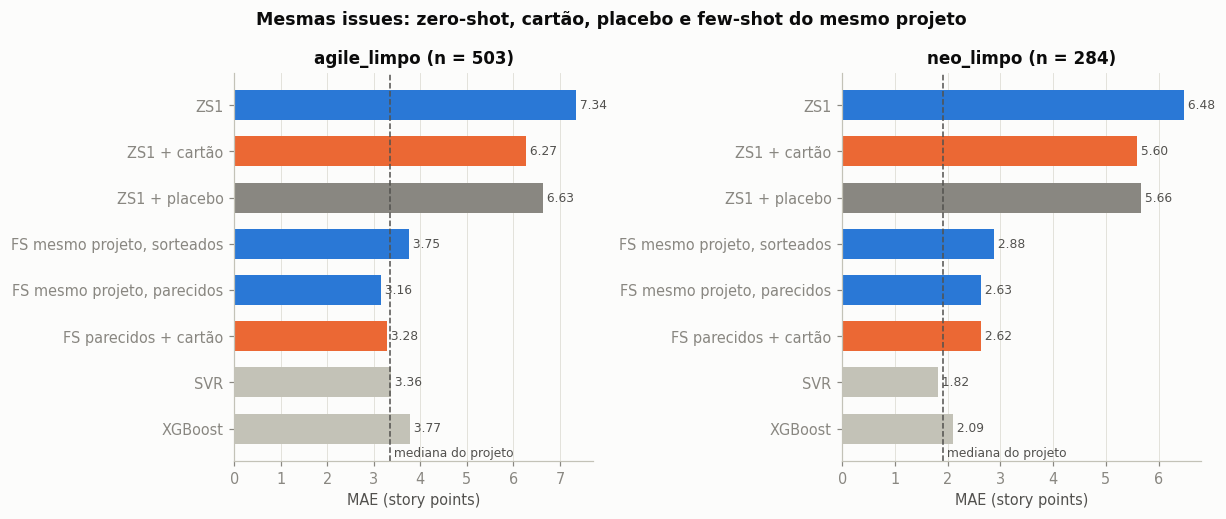

In [5]:
if rows_mae:
    ordem = [n for n in [*CONFIGS, "SVR", "XGBoost"] if n in MAE1.index.get_level_values(1)]
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.6 * len(DATASETS), 0.42 * len(ordem) + 1.4))
    for ax, ds in zip(np.atleast_1d(axes), DATASETS):
        if ds not in MAE1.index.get_level_values(0):
            ax.set_visible(False); continue
        sub = MAE1.loc[ds].reindex(ordem).dropna(subset=["MAE"])
        cores = [COR["s2"] if "cartão" in n else COR["muted"] if "placebo" in n else
                 COR["axis"] if n in REFERENCIAS else COR["s1"] for n in sub.index]
        ax.barh(range(len(sub)), sub.MAE, color=cores, height=0.65)
        for i, v in enumerate(sub.MAE):
            ax.text(v, i, f" {v:.2f}", va="center", fontsize=8, color=COR["ink2"])
        if "ProjectMedian" in MAE1.loc[ds].index:
            pm = MAE1.loc[(ds, "ProjectMedian"), "MAE"]
            ax.axvline(pm, color=COR["ink2"], linestyle="--", linewidth=1)
            ax.text(pm, len(sub) - 0.4, " mediana do projeto", fontsize=8, color=COR["ink2"])
        ax.set_yticks(range(len(sub))); ax.set_yticklabels(sub.index); ax.invert_yaxis()
        ax.set_xlabel("MAE (story points)"); ax.set_title(f"{ds} (n = {int(sub.n.iloc[0])})"); ax.grid(axis="y", visible=False)
    fig.suptitle("Mesmas issues: zero-shot, cartão, placebo e few-shot do mesmo projeto", fontweight="bold", color=COR["ink"])
    fig.tight_layout(); salva_fig("parte1_mae"); plt.show()

### 1c. O subconjunto com cartão é representativo?

As comparações acima só usam issues de projetos com repositório no GitHub. Aqui, o mesmo modelo nas issues de
avaliação **com** e **sem** cartão. Se os erros forem parecidos, o que vale no subconjunto provavelmente vale no
resto; se não forem, isso vai para as ameaças à validade.

In [6]:
def pred_de(ds, nome, ids):
    return P1[(ds, nome)].loc[ids, "y_pred"].astype(float).fillna(TRAIN_MED[ds])

rows = []
for ds in DATASETS:
    if (ds, "ZS1 + cartão") not in P1:
        continue
    d = load_merged(ds)
    ev = d[d.within_eval == 1].set_index("issue_id")
    com = ev.index.isin(P1[(ds, "ZS1 + cartão")].index)
    grupo = pd.Series(np.where(com, "com cartão", "sem cartão"), index=ev.index)
    sp = ev.sp.astype(float)
    rows.append({"dataset": ds, "medida": "SP real (média)", "com cartão": sp[com].mean(), "sem cartão": sp[~com].mean(),
                 "n com": int(com.sum()), "n sem": int((~com).sum()),
                 "p (Mann-Whitney)": stats.mannwhitneyu(sp[com], sp[~com]).pvalue})
    rows.append({"dataset": ds, "medida": "projetos", "com cartão": ev[com].project.nunique(),
                 "sem cartão": ev[~com].project.nunique(), "n com": int(com.sum()), "n sem": int((~com).sum())})
    for nome in ["ZS1", "ProjectMedian", "XGBoost", "SVR", "FS mesmo projeto, parecidos"]:
        if (ds, nome) not in P1:
            continue
        ids = ev.index.intersection(P1[(ds, nome)].index)
        err = (ev.loc[ids, "sp"].astype(float) - pred_de(ds, nome, ids)).abs()
        a, b = err[grupo.loc[ids] == "com cartão"], err[grupo.loc[ids] == "sem cartão"]
        if len(a) < 5 or len(b) < 5:
            continue
        rows.append({"dataset": ds, "medida": f"MAE {nome}", "com cartão": a.mean(), "sem cartão": b.mean(),
                     "n com": len(a), "n sem": len(b), "p (Mann-Whitney)": stats.mannwhitneyu(a, b).pvalue})
if rows:
    REPR = pd.DataFrame(rows).set_index(["dataset", "medida"])
    display(REPR, nome="P1 representatividade")
    print("Few-shot só aparece aqui se tiver rodado também nas issues sem cartão (comando 5 da configuração).")

com cartão  sem cartão  n com  n sem  p (Mann-Whitney)
dataset     medida                                                                                 
agile_limpo SP real (média)                       5.660       6.828    503    528             0.001
            projetos                              8.000       8.000    503    528               NaN
            MAE ZS1                               7.344       7.116    503    528             0.103
            MAE ProjectMedian                     3.356       4.220    503    528             0.003
            MAE XGBoost                           3.770       4.288    503    528             0.005
            MAE SVR                               3.362       3.951    503    528             0.011
            MAE FS mesmo projeto, parecidos       3.157       4.288    503    528             0.001
neo_limpo   SP real (média)                       3.391       2.859    284    432             0.022
            projetos                              9.000      19.000    284    432               NaN
            MAE ZS1                               6.482       6.785    284    432             0.529
            MAE ProjectMedian                     1.908       1.426    284    432             0.000
            MAE XGBoost                           2.092       1.381    284    432             0.001
            MAE SVR                               1.819       1.459    284    432             0.008
            MAE FS mesmo projeto, parecidos       2.627       1.706    284    432             0.000

Few-shot só aparece aqui se tiver rodado também nas issues sem cartão (comando 5 da configuração).


### 1d. Combinar o LLM por analogia com a mediana do projeto

Média simples (peso 0,5 fixo, escolhido **antes** de olhar o teste) das predições do few-shot e da mediana do
projeto. Os dois erram de jeitos diferentes: a mediana ignora o texto, e o LLM lê o texto mas oscila. Se a média
ganhar dos dois, é o resultado a destacar. A mesma combinação com o XGBoost mostra se o ganho é do LLM ou de
qualquer modelo que leia o texto.

In [7]:
COMBOS = {"média(mediana do projeto, FS parecidos)": ("ProjectMedian", "FS mesmo projeto, parecidos"),
          "média(mediana do projeto, FS parecidos + cartão)": ("ProjectMedian", "FS parecidos + cartão"),
          "média(mediana do projeto, XGBoost)": ("ProjectMedian", "XGBoost")}
rows_m, rows_c2 = [], []
for ds in DATASETS:
    if ds not in E1:
        continue
    ids = list(E1[ds].index)
    y = P1[(ds, "ProjectMedian")].loc[ids, "y_true"].astype(float)
    E = E1[ds].copy()
    for nome, (a, b) in COMBOS.items():
        if a in E and b in E:
            E[nome] = (y - (pred_de(ds, a, ids) + pred_de(ds, b, ids)) / 2).abs()
    for n in ["ProjectMedian", "FS mesmo projeto, parecidos", "XGBoost", *COMBOS]:
        if n in E:
            rows_m.append({"dataset": ds, "configuração": n, "MAE": E[n].mean(), "MdAE": E[n].median(), "n": len(E)})
    fam = []
    for nome, (a, b) in COMBOS.items():
        if nome not in E:
            continue
        for ref in dict.fromkeys(["ProjectMedian", b]):
            r = wilcoxon_pareado(E[ref], E[nome]); lo, hi = bootstrap_ci(E[nome] - E[ref])
            fam.append({"dataset": ds, "combinação": nome, "contra": ref, "MAE ref": E[ref].mean(), "MAE combinação": E[nome].mean(),
                        "Δ MAE": r["Δ média"], "IC95% inf": lo, "IC95% sup": hi, "p (Wilcoxon)": r["p (Wilcoxon)"], "n": r["n"]})
    if fam:
        fam = pd.DataFrame(fam); fam["p (Holm)"] = holm(fam["p (Wilcoxon)"]).values; rows_c2.append(fam)
if rows_m:
    display(pd.DataFrame(rows_m).set_index(["dataset", "configuração"]), nome="P1 combinação MAE")
if rows_c2:
    COMB = pd.concat(rows_c2).set_index(["dataset", "combinação", "contra"])
    COMB.to_csv(OUT / "parte1_combinacao.csv")
    display(COMB, nome="P1 combinação contrastes")
    print("Δ negativo = a combinação errou menos que a referência.")

MAE  MdAE    n
dataset     configuração                                                     
agile_limpo ProjectMedian                                    3.356 2.000  503
            FS mesmo projeto, parecidos                      3.157 2.000  503
            XGBoost                                          3.770 2.168  503
            média(mediana do projeto, FS parecidos)          3.016 1.500  503
            média(mediana do projeto, FS parecidos + cartão) 3.157 1.500  503
            média(mediana do projeto, XGBoost)               3.398 1.802  503
neo_limpo   ProjectMedian                                    1.908 1.000  284
            FS mesmo projeto, parecidos                      2.627 2.000  284
            XGBoost                                          2.092 1.126  284
            média(mediana do projeto, FS parecidos)          2.067 1.500  284
            média(mediana do projeto, FS parecidos + cartão) 2.026 1.500  284
            média(mediana do projeto, XGBoost)               1.926 1.050  284

MAE ref  MAE combinação  Δ MAE  IC95% inf  IC95% sup  p (Wilcoxon)  \
dataset     combinação                                       contra                                                                                            
agile_limpo média(mediana do projeto, FS parecidos)          ProjectMedian                  3.356           3.016 -0.340     -0.637     -0.105         0.010   
                                                             FS mesmo projeto, parecidos    3.157           3.016 -0.141     -0.416      0.152         0.034   
            média(mediana do projeto, FS parecidos + cartão) ProjectMedian                  3.356           3.157 -0.199     -0.393     -0.023         0.151   
                                                             FS parecidos + cartão          3.281           3.157 -0.125     -0.312      0.075         0.008   
            média(mediana do projeto, XGBoost)               ProjectMedian                  3.356           3.398  0.042     -0.116      0.189         0.002   
                                                             XGBoost                        3.770           3.398 -0.373     -0.541     -0.206         0.000   
neo_limpo   média(mediana do projeto, FS parecidos)          ProjectMedian                  1.908           2.067  0.158     -0.049      0.389         0.044   
                                                             FS mesmo projeto, parecidos    2.627           2.067 -0.560     -0.785     -0.359         0.000   
            média(mediana do projeto, FS parecidos + cartão) ProjectMedian                  1.908           2.026  0.118     -0.097      0.350         0.077   
                                                             FS parecidos + cartão          2.623           2.026 -0.597     -0.815     -0.394         0.000   
            média(mediana do projeto, XGBoost)               ProjectMedian                  1.908           1.926  0.017     -0.098      0.159         0.686   
                                                             XGBoost                        2.092           1.926 -0.167     -0.367     -0.022         0.056   

                                                                                            n  p (Holm)  
dataset     combinação                                       contra                                      
agile_limpo média(mediana do projeto, FS parecidos)          ProjectMedian                503     0.033  
                                                             FS mesmo projeto, parecidos  503     0.069  
            média(mediana do projeto, FS parecidos + cartão) ProjectMedian                503     0.151  
                                                             FS parecidos + cartão        503     0.033  
            média(mediana do projeto, XGBoost)               ProjectMedian                503     0.011  
                                                             XGBoost                      503     0.000  
neo_limpo   média(mediana do projeto, FS parecidos)          ProjectMedian                284     0.176  
                                                             FS mesmo projeto, parecidos  284     0.000  
            média(mediana do projeto, FS parecidos + cartão) ProjectMedian                284     0.176  
                                                             FS parecidos + cartão        284     0.000  
            média(mediana do projeto, XGBoost)               ProjectMedian                284     0.686  
                                                             XGBoost                      284     0.176

Δ negativo = a combinação errou menos que a referência.


### 1e. Few-shot por analogia no dataset inteiro

O few-shot com exemplos do mesmo projeto não precisa de cartão, então pode valer para **todas** as issues. Esta
célula só roda se o comando 5 da configuração já tiver estimado as issues sem cartão.

In [8]:
rows_m, rows_c3 = [], []
FS = "FS mesmo projeto, parecidos"
for ds in DATASETS:
    if (ds, FS) not in P1 or (ds, "ZS1") not in P1:
        continue
    ev = load_merged(ds).query("within_eval == 1").issue_id
    ids = sorted(set(ev) & set(P1[(ds, FS)].index) & set(P1[(ds, "ZS1")].index) & set(P1[(ds, "ProjectMedian")].index))
    n_cartao = len(P1[(ds, "ZS1 + cartão")].index) if (ds, "ZS1 + cartão") in P1 else 0
    if len(ids) <= n_cartao:
        print(f"[{ds}] o few-shot ainda só cobre as {len(ids)} issues com cartão (de {len(ev)}): rode o comando 5.")
        continue
    y = P1[(ds, "ProjectMedian")].loc[ids, "y_true"].astype(float)
    E = pd.DataFrame(index=ids)
    for n in ["ZS1", FS, "ProjectMedian", "XGBoost", "SVR"]:
        if (ds, n) in P1 and set(ids) <= set(P1[(ds, n)].index):
            E[n] = (y - pred_de(ds, n, ids)).abs()
    E["média(mediana do projeto, FS parecidos)"] = (y - (pred_de(ds, "ProjectMedian", ids) + pred_de(ds, FS, ids)) / 2).abs()
    for n in E:
        rows_m.append({"dataset": ds, "configuração": n, "MAE": E[n].mean(), "MdAE": E[n].median(), "n": len(E),
                       "de": len(ev)})
    fam = []
    for a, b in [("ZS1", FS), ("ProjectMedian", FS), ("ProjectMedian", "média(mediana do projeto, FS parecidos)"),
                 (FS, "média(mediana do projeto, FS parecidos)")]:
        r = wilcoxon_pareado(E[a], E[b]); lo, hi = bootstrap_ci(E[b] - E[a])
        fam.append({"dataset": ds, "A": a, "B": b, "MAE A": E[a].mean(), "MAE B": E[b].mean(), "Δ MAE (B − A)": r["Δ média"],
                    "IC95% inf": lo, "IC95% sup": hi, "p (Wilcoxon)": r["p (Wilcoxon)"], "n": r["n"]})
    fam = pd.DataFrame(fam); fam["p (Holm)"] = holm(fam["p (Wilcoxon)"]).values; rows_c3.append(fam)
if rows_m:
    display(pd.DataFrame(rows_m).set_index(["dataset", "configuração"]), nome="P1 dataset inteiro MAE")
if rows_c3:
    INT = pd.concat(rows_c3).set_index(["dataset", "A", "B"])
    INT.to_csv(OUT / "parte1_dataset_inteiro.csv")
    display(INT, nome="P1 dataset inteiro contrastes")

MAE  MdAE     n    de
dataset     configuração                                                   
agile_limpo ZS1                                     7.227 7.000  1031  1031
            FS mesmo projeto, parecidos             3.736 2.000  1031  1031
            ProjectMedian                           3.798 2.000  1031  1031
            XGBoost                                 4.036 2.441  1031  1031
            SVR                                     3.664 2.029  1031  1031
            média(mediana do projeto, FS parecidos) 3.470 1.500  1031  1031
neo_limpo   ZS1                                     6.665 6.000   716   716
            FS mesmo projeto, parecidos             2.071 1.000   716   716
            ProjectMedian                           1.617 1.000   716   716
            XGBoost                                 1.663 1.004   716   716
            SVR                                     1.602 0.900   716   716
            média(mediana do projeto, FS parecidos) 1.671 1.000   716   716

MAE A  MAE B  Δ MAE (B − A)  IC95% inf  IC95% sup  p (Wilcoxon)     n  \
dataset     A                           B                                                                                                                
agile_limpo ZS1                         FS mesmo projeto, parecidos              7.227  3.736         -3.491     -3.870     -3.115         0.000  1031   
            ProjectMedian               FS mesmo projeto, parecidos              3.798  3.736         -0.062     -0.403      0.263         0.941  1031   
                                        média(mediana do projeto, FS parecidos)  3.798  3.470         -0.328     -0.519     -0.145         0.001  1031   
            FS mesmo projeto, parecidos média(mediana do projeto, FS parecidos)  3.736  3.470         -0.266     -0.483     -0.053         0.007  1031   
neo_limpo   ZS1                         FS mesmo projeto, parecidos              6.665  2.071         -4.594     -4.912     -4.286         0.000   716   
            ProjectMedian               FS mesmo projeto, parecidos              1.617  2.071          0.454      0.219      0.690         0.000   716   
                                        média(mediana do projeto, FS parecidos)  1.617  1.671          0.054     -0.069      0.179         0.030   716   
            FS mesmo projeto, parecidos média(mediana do projeto, FS parecidos)  2.071  1.671         -0.400     -0.524     -0.270         0.000   716   

                                                                                 p (Holm)  
dataset     A                           B                                                  
agile_limpo ZS1                         FS mesmo projeto, parecidos                 0.000  
            ProjectMedian               FS mesmo projeto, parecidos                 0.941  
                                        média(mediana do projeto, FS parecidos)     0.002  
            FS mesmo projeto, parecidos média(mediana do projeto, FS parecidos)     0.014  
neo_limpo   ZS1                         FS mesmo projeto, parecidos                 0.000  
            ProjectMedian               FS mesmo projeto, parecidos                 0.000  
                                        média(mediana do projeto, FS parecidos)     0.030  
            FS mesmo projeto, parecidos média(mediana do projeto, FS parecidos)     0.000

### 1f. Calibração por tipo da issue (metadados do tracker)

O `32_ml_metadados.py` mostrou que, no Agile, a **mediana do projeto × tipo da issue** (bug, story, task...) ganha
da mediana do projeto. Aqui ela vira a referência a vencer, e entram:
- `ZS1 + dist. SP por tipo`: o LLM recebe a distribuição de SP do time **para o mesmo tipo de issue**
  (`30_run_llm.py --dist-sp --dist-sp-por tipo`);
- **combinações** (média simples, peso 0,5 fixo) da mediana projeto × tipo com o few-shot por analogia, com o
  XGBoost texto + metadados (`32`) e com o LLM calibrado por tipo. Nenhuma chamada nova de LLM.

Mesmas issues em todas as linhas: no Agile, só as encontradas no TAWOS (12 projetos); no NEO, todas. Uma configuração
que ainda não rodou fica de fora. Respostas fora da faixa → mediana do treino (a regra de validade da parte 1).

In [9]:
from see.metadados import tipos as tipos_de, mediana_projeto_tipo
CFG_TIPO = {"ZS1": ("within", f"{LLM}__ZS1.csv"),
            "ZS1 + dist. SP do projeto": ("within", f"{LLM}__ZS1__distsp.csv"),
            "ZS1 + dist. SP por tipo": ("within", f"{LLM}__ZS1__distsptipo.csv"),
            "FS mesmo projeto, parecidos": ("within_fewshot_simproj", f"{LLM}__FS1__similar_same_project.csv"),
            "XGBoost (texto)": ("within", "XGBoost.csv"),
            "XGBoost texto+meta": ("within_meta", "XGBoost+meta.csv")}
COMBOS_T = {"média(PM×tipo, FS parecidos)": "FS mesmo projeto, parecidos",
            "média(PM×tipo, XGBoost texto+meta)": "XGBoost texto+meta",
            "média(PM×tipo, ZS1 + dist. SP por tipo)": "ZS1 + dist. SP por tipo"}
rows_m, rows_c = [], []
for ds in DATASETS:
    try:
        T = tipos_de(ds)
    except FileNotFoundError as e:
        print(f"[{ds}] {e}"); continue
    d = load_merged(ds)
    ev, tr = d[d.within_eval == 1], d[d.within == "train"]
    if config.base_dataset(ds) == "agile":            # só as issues com metadados do TAWOS (como no 32)
        ev, tr = ev[ev.issue_id.isin(T.index)], tr[tr.issue_id.isin(T.index)]
    ev = ev.reset_index(drop=True)
    P = {"ProjectMedian": ev.project.map(tr.groupby("project").sp.median()).fillna(tr.sp.median()).to_numpy(float),
         "ProjectMedian×tipo": mediana_projeto_tipo(tr, ev, T)}
    cobertura = {}
    for nome, (proto, arq) in CFG_TIPO.items():
        f = config.PREDICTIONS / ds / proto / arq
        if not f.exists():
            continue
        p = pd.read_csv(f, dtype={"issue_id": str}).drop_duplicates("issue_id").set_index("issue_id")
        cobertura[nome] = ev.issue_id.isin(p.index).mean()
        if cobertura[nome] < 0.95:
            print(f"[{ds}] {nome}: cobre só {100 * cobertura[nome]:.0f}% das issues; fica de fora"); continue
        P[nome] = na_faixa(ev.issue_id.map(p.y_pred), ds)
    cobertos = ev.issue_id
    for nome in [n for n in CFG_TIPO if n in P]:
        f = config.PREDICTIONS / ds / CFG_TIPO[nome][0] / CFG_TIPO[nome][1]
        cobertos = cobertos[cobertos.isin(pd.read_csv(f, dtype={"issue_id": str}).issue_id)]
    sel = ev.issue_id.isin(cobertos).to_numpy()
    y = ev.sp.astype(float).to_numpy()[sel]
    Pn = {k: np.asarray(pd.Series(v).fillna(TRAIN_MED[ds]), dtype=float)[sel] for k, v in P.items()}
    for nome, base in COMBOS_T.items():
        if base in Pn:
            Pn[nome] = (Pn["ProjectMedian×tipo"] + Pn[base]) / 2
    E = pd.DataFrame({k: np.abs(y - v) for k, v in Pn.items()})
    for k in E:
        rows_m.append({"dataset": ds, "configuração": k, "MAE": E[k].mean(), "MdAE": E[k].median(), "n": len(E)})
    fam = []
    pares = [("ProjectMedian", "ProjectMedian×tipo", "tipo na mediana")]
    pares += [("ZS1 + dist. SP do projeto", "ZS1 + dist. SP por tipo", "LLM: dist. por tipo × do projeto")]
    pares += [("ProjectMedian×tipo", k, f"{k} × PM×tipo") for k in E if k not in ("ProjectMedian", "ProjectMedian×tipo", "ZS1")]
    for a, b, desc in pares:
        if a in E and b in E:
            r = wilcoxon_pareado(E[a], E[b]); lo, hi = bootstrap_ci(E[b] - E[a])
            fam.append({"dataset": ds, "contraste": desc, "A": a, "B": b, "MAE A": E[a].mean(), "MAE B": E[b].mean(),
                        "Δ MAE (B − A)": r["Δ média"], "IC95% inf": lo, "IC95% sup": hi,
                        "p (Wilcoxon)": r["p (Wilcoxon)"], "n": r["n"]})
    if fam:
        fam = pd.DataFrame(fam); fam["p (Holm)"] = holm(fam["p (Wilcoxon)"]).values; rows_c.append(fam)
if rows_m:
    display(pd.DataFrame(rows_m).set_index(["dataset", "configuração"]), nome="P1f MAE calibração por tipo")
if rows_c:
    CT = pd.concat(rows_c).set_index(["dataset", "contraste"])
    CT.to_csv(OUT / "parte1f_calibracao_tipo.csv")
    display(CT, nome="P1f contrastes")
    print("Δ negativo = B errou menos que A. A pergunta é se algo ganha da mediana projeto × tipo (linhas '× PM×tipo').")

MAE  MdAE    n
dataset     configuração                                            
agile_limpo ProjectMedian                           3.997 2.000  884
            ProjectMedian×tipo                      3.586 2.000  884
            ZS1                                     7.303 6.000  884
            ZS1 + dist. SP do projeto               4.128 2.000  884
            ZS1 + dist. SP por tipo                 3.669 2.000  884
            FS mesmo projeto, parecidos             3.900 2.000  884
            XGBoost (texto)                         4.180 2.412  884
            XGBoost texto+meta                      3.750 1.972  884
            média(PM×tipo, FS parecidos)            3.471 1.500  884
            média(PM×tipo, XGBoost texto+meta)      3.519 1.867  884
            média(PM×tipo, ZS1 + dist. SP por tipo) 3.555 1.500  884
neo_limpo   ProjectMedian                           1.617 1.000  716
            ProjectMedian×tipo                      1.599 1.000  716
            ZS1                                     6.665 6.000  716
            ZS1 + dist. SP do projeto               1.682 1.000  716
            ZS1 + dist. SP por tipo                 1.628 1.000  716
            FS mesmo projeto, parecidos             2.071 1.000  716
            XGBoost (texto)                         1.663 1.004  716
            XGBoost texto+meta                      1.553 0.934  716
            média(PM×tipo, FS parecidos)            1.671 1.000  716
            média(PM×tipo, XGBoost texto+meta)      1.511 0.928  716
            média(PM×tipo, ZS1 + dist. SP por tipo) 1.605 1.000  716

A                                        B  MAE A  MAE B  \
dataset     contraste                                                                                                                             
agile_limpo tipo na mediana                                                ProjectMedian                       ProjectMedian×tipo  3.997  3.586   
            LLM: dist. por tipo × do projeto                   ZS1 + dist. SP do projeto                  ZS1 + dist. SP por tipo  4.128  3.669   
            ZS1 + dist. SP do projeto × PM×tipo                       ProjectMedian×tipo                ZS1 + dist. SP do projeto  3.586  4.128   
            ZS1 + dist. SP por tipo × PM×tipo                         ProjectMedian×tipo                  ZS1 + dist. SP por tipo  3.586  3.669   
            FS mesmo projeto, parecidos × PM×tipo                     ProjectMedian×tipo              FS mesmo projeto, parecidos  3.586  3.900   
            XGBoost (texto) × PM×tipo                                 ProjectMedian×tipo                          XGBoost (texto)  3.586  4.180   
            XGBoost texto+meta × PM×tipo                              ProjectMedian×tipo                       XGBoost texto+meta  3.586  3.750   
            média(PM×tipo, FS parecidos) × PM×tipo                    ProjectMedian×tipo             média(PM×tipo, FS parecidos)  3.586  3.471   
            média(PM×tipo, XGBoost texto+meta) × PM×tipo              ProjectMedian×tipo       média(PM×tipo, XGBoost texto+meta)  3.586  3.519   
            média(PM×tipo, ZS1 + dist. SP por tipo) × PM×tipo         ProjectMedian×tipo  média(PM×tipo, ZS1 + dist. SP por tipo)  3.586  3.555   
neo_limpo   tipo na mediana                                                ProjectMedian                       ProjectMedian×tipo  1.617  1.599   
            LLM: dist. por tipo × do projeto                   ZS1 + dist. SP do projeto                  ZS1 + dist. SP por tipo  1.682  1.628   
            ZS1 + dist. SP do projeto × PM×tipo                       ProjectMedian×tipo                ZS1 + dist. SP do projeto  1.599  1.682   
            ZS1 + dist. SP por tipo × PM×tipo                         ProjectMedian×tipo                  ZS1 + dist. SP por tipo  1.599  1.628   
            FS mesmo projeto, parecidos × PM×tipo                     ProjectMedian×tipo              FS mesmo projeto, parecidos  1.599  2.071   
            XGBoost (texto) × PM×tipo                                 ProjectMedian×tipo                          XGBoost (texto)  1.599  1.663   
            XGBoost texto+meta × PM×tipo                              ProjectMedian×tipo                       XGBoost texto+meta  1.599  1.553   
            média(PM×tipo, FS parecidos) × PM×tipo                    ProjectMedian×tipo             média(PM×tipo, FS parecidos)  1.599  1.671   
            média(PM×tipo, XGBoost texto+meta) × PM×tipo              ProjectMedian×tipo       média(PM×tipo, XGBoost texto+meta)  1.599  1.511   
            média(PM×tipo, ZS1 + dist. SP por tipo) × PM×tipo         ProjectMedian×tipo  média(PM×tipo, ZS1 + dist. SP por tipo)  1.599  1.605   

                                                               Δ MAE (B − A)  IC95% inf  IC95% sup  p (Wilcoxon)    n  p (Holm)  
dataset     contraste                                                                                                            
agile_limpo tipo na mediana                                           -0.411     -0.667     -0.170         0.001  884     0.004  
            LLM: dist. por tipo × do projeto                          -0.459     -0.876     -0.084         0.004  884     0.024  
            ZS1 + dist. SP do projeto × PM×tipo                        0.542      0.283      0.817         0.000  884     0.001  
            ZS1 + dist. SP por tipo × PM×tipo                          0.083     -0.198      0.353         0.385  884     0.770  
            FS mesmo projeto, parecidos × PM×tipo                      0

Δ negativo = B errou menos que A. A pergunta é se algo ganha da mediana projeto × tipo (linhas '× PM×tipo').


---
# Parte 2 — Reescrita estruturada pelos fatores de esforço

Usa as issues da seção 12 do `analise_jev.ipynb` (`results/improvement/selecionadas_contexto.csv`) que têm as
8 estimativas do fatorial (4 versões × cartão sim/não, caches `llm_{modelo}_{versão}[__cartao].jsonl`). Nada disso
é refeito: só a versão nova é gerada, julgada pelo Jev e estimada. Caches novos:
`rewrites_estruturar_contexto_*.jsonl`, `jev_estruturar_contexto.jsonl`, `llm_{modelo}_estruturar_contexto[__cartao].jsonl`
e `pred_{dataset}_{modelo}_estruturar.csv`.

**Outro reescritor:** com `REWRITER` diferente do llama3, a versão nova se chama `estruturar_contexto__{modelo}`
(caches próprios) e a do llama3 entra ao lado dela na comparação. O estimador não muda, então a diferença entre as
duas é só a qualidade da reescrita.

In [10]:
VERSOES_12 = ["original", "parafrasear", "melhorar", "melhorar_contexto"]
BASE_E = "estruturar_contexto"                 # a versão feita pelo llama3 (primeira rodada)
_slug = lambda m: re.sub(r'[^A-Za-z0-9._-]', '-', m)
NOVA = BASE_E if REWRITER["model"] == "llama3" else f"{BASE_E}__{_slug(REWRITER['model'])}"
pred_tag = lambda v: v.replace(BASE_E, "estruturar")        # nome do cache do ML: pred_{ds}_{modelo}_{tag}.csv
SLUG_EST = re.sub(r'[^A-Za-z0-9._-]', '-', ESTIMADOR_LLM["model"]) if ESTIMADOR_LLM else None

def le_cache_llm(versao, com_cartao):
    path = EXP / f"llm_{SLUG_EST}_{versao}{'__cartao' if com_cartao else ''}.jsonl"
    done = {}
    if path.exists():
        for line in path.read_text(encoding="utf-8").splitlines():
            if line.strip():
                r = json.loads(line); done[r["issue_id"]] = r
    return path, done

PARTE2 = RODAR_PARTE_2 and ESTIMADOR_LLM is not None
sel_path = EXP / "selecionadas_contexto.csv"
if PARTE2 and not sel_path.exists():
    print("Falta results/improvement/selecionadas_contexto.csv: rode a seção 12 do analise_jev.ipynb antes."); PARTE2 = False
if PARTE2:
    SELC = pd.read_csv(sel_path, dtype={"issue_id": str, "project": str})
    SELC = SELC[SELC.dataset.isin(DATASETS)]
    EXTRA = []                                   # versão do llama3 ao lado de um reescritor novo
    if NOVA != BASE_E and all(le_cache_llm(BASE_E, c)[0].exists() for c in (False, True)):
        EXTRA = [BASE_E]
    VERSOES_ANT = VERSOES_12 + EXTRA             # versões que só são lidas dos caches
    print(f"versão nova: {NOVA}" + (f" (comparada também com {BASE_E}, do llama3)" if EXTRA else ""))
    ids2 = set(SELC.issue_id)
    for v in VERSOES_ANT:
        for c in (False, True):
            ids2 &= set(le_cache_llm(v, c)[1])
    print(f"{len(ids2)} das {len(SELC)} issues da seção 12 têm as {2 * len(VERSOES_ANT)} estimativas já feitas "
          f"({SELC[SELC.issue_id.isin(ids2)].groupby('dataset').size().to_dict()})")
    if not ids2:
        print("Nenhuma: rode a seção 12 (12d) do analise_jev.ipynb até o fim antes."); PARTE2 = False

if PARTE2:
    # texto original e notas do Jev das issues (os mesmos arquivos que o analise_jev.ipynb lê)
    QUESTIONS = json.loads((ROOT / "quality_criteria.json").read_text(encoding="utf-8"))
    QUESTIONS = {k: v for k, v in QUESTIONS.items() if not k.startswith("_")}
    frames = []
    for ds in DATASETS:
        j = add_quality_scores(pd.read_csv(config.RESULTS / "quality" / f"{ds}{'' if SUBSET == 'eval' else '_' + SUBSET}__{ENGINE}.csv",
                                           dtype={"issue_id": str, "project": str}))
        data = load_merged(ds)
        j = j.drop(columns=["project", "sp"], errors="ignore").merge(
            data[["issue_id", "project", "sp", "title", "description", "within"]], on="issue_id", how="left")
        j["dataset"] = ds
        frames.append(j)
    J = pd.concat(frames, ignore_index=True)
    J = J[J.issue_id.isin(ids2)]
    CARDS = pd.read_csv(config.DATA_PROCESSED / "project_cards.csv", dtype={"project": str}).fillna("")
    CARD = {(r.dataset, r.project): (r.cartao or r.cartao_bruto) for r in CARDS.itertuples()}
    cartao = lambda ds, p: CARD.get((config.base_dataset(ds), str(p)))
    ORIG = J[["issue_id", "dataset", "project", "sp", "title", "description"]].copy()
    ORIG["title"] = ORIG.title.map(clean_light); ORIG["description"] = ORIG.description.fillna("").map(clean_light)
    ORIG = ORIG.sort_values(["dataset", "issue_id"]).reset_index(drop=True)

versão nova: estruturar_contexto
135 das 200 issues da seção 12 têm as 8 estimativas já feitas ({'agile_limpo': 82, 'neo_limpo': 53})


In [11]:
# ---- 2a. reescrita estruturada (com o cartão do projeto) ----
from see.llm_clients import LLMClient, call_with_retry

CAMPOS = ["Type", "Goal", "Scope", "Affected components", "Technologies", "External dependencies",
          "Acceptance criteria", "Open questions"]
CAMPOS_LACUNA = ["Goal", "Scope", "Affected components", "Technologies", "Acceptance criteria"]   # informação da issue

PROMPT_ESTRUTURAR = '''You are a Quality Analyst on an agile team. Rewrite the work item below into the structured template that follows. The template lists the information an agile team needs to estimate a work item (effort drivers). You also receive background about the project, as a member of the team would know it.

Rules:
- Use ONLY information stated in the original work item or directly supported by the project context. Do NOT invent features, requirements, numbers, components or acceptance criteria.
- When the information for a field is not available, write exactly "Not stated". Do not guess.
- Preserve every technical detail of the original (error messages, file names, versions, steps to reproduce).
- Never mention effort, size, complexity, time or story points.

Template for the description (keep the field names, one field per line, in this order):
Type: <bug | feature | improvement | technical task | documentation | Not stated>
Goal: <what must be achieved and why, in one or two sentences>
Scope: <what has to be changed or built; list the subtasks if the original implies them>
Affected components: <modules, screens, services, APIs or files involved>
Technologies: <languages, frameworks, libraries, databases or platforms involved>
External dependencies: <other teams, third-party services, hardware or upstream issues>
Acceptance criteria: <verifiable conditions, only if they can be inferred>
Open questions: <what is unclear or missing in the original>

Project context:
{context}

Original work item:
Title: {title}
Description: {description}

Respond ONLY with valid JSON: {{"title": "...", "description": "<the filled template>", "justification": "..."}}'''

PLACEHOLDER = re.compile(r"^\s*(\.{2,}|…|<[^>]*>|n/?a|none|null|tbd)?\s*$", re.I)
FORBIDDEN = re.compile(r"story ?points?|\bpoints?\b|\bhours?\b|\bdays?\b|effort|estimat", re.I)
_ROTULO = re.compile(r"(?im)^[\s*#>\-]*(" + "|".join(re.escape(c) for c in CAMPOS) + r")\s*\**\s*:")

def campos(desc):
    # separa a descrição estruturada nos campos do modelo: {campo: texto}
    marcas = [(m.start(), m.end(), m.group(1).lower()) for m in _ROTULO.finditer(desc or "")]
    out = {}
    for k, (ini, fim, nome) in enumerate(marcas):
        prox = marcas[k + 1][0] if k + 1 < len(marcas) else len(desc)
        nome = next(c for c in CAMPOS if c.lower() == nome)
        out.setdefault(nome, desc[fim:prox].strip(" \n*-"))
    return out

def nao_informado(txt):
    return txt is None or not re.sub(r"[\s.*_\-]", "", txt) or bool(re.fullmatch(r"\W*not stated\W*", txt.strip(), re.I))

def parse_json(text):
    text = re.sub(r"<think>.*?</think>", " ", text or "", flags=re.S)
    m = re.search(r"\{.*\}", text, flags=re.S)
    if not m:
        return None
    try:
        d = json.loads(m.group(0), strict=False)       # aceita quebra de linha dentro das strings
    except json.JSONDecodeError:
        return None
    if isinstance(d.get("description"), dict):          # o modelo às vezes devolve os campos como objeto
        d["description"] = "\n".join(f"{k}: {v}" for k, v in d["description"].items())
    if isinstance(d.get("description"), list):
        d["description"] = "\n".join(map(str, d["description"]))
    return d if isinstance(d.get("title"), str) and isinstance(d.get("description"), str) else None

def valida(d, original_desc):
    if not d or PLACEHOLDER.match(d["title"]):
        return False
    if original_desc.strip() and PLACEHOLDER.match(d["description"]):
        return False
    return len(campos(d["description"])) >= 5            # seguiu o modelo (pelo menos 5 dos 8 campos)

def done_ids(path):
    out = {}
    if path.exists():
        for line in path.read_text(encoding="utf-8").splitlines():
            if line.strip():
                r = json.loads(line)
                if r.get("ok"):
                    out[r["issue_id"]] = r
    return out

_KEYS = {"gemini": "GEMINI_API_KEY", "groq": "GROQ_API_KEY", "openrouter": "OPENROUTER_API_KEY"}
if PARTE2:
    if REWRITER["provider"] in _KEYS:
        pedir_chave(_KEYS[REWRITER["provider"]], "quem reescreve")
    rewriter = LLMClient(REWRITER["provider"], REWRITER["model"], temperature=0.0, max_tokens=1500, seed=config.SEED)
    versao = hashlib.sha1((PROMPT_ESTRUTURAR + rewriter.model).encode()).hexdigest()[:8]
    REW_PATH = EXP / f"rewrites_{BASE_E}_{_slug(rewriter.model)}_{versao}.jsonl"
    done = done_ids(REW_PATH)
    tentadas = set()
    if REW_PATH.exists():
        tentadas = {json.loads(l)["issue_id"] for l in REW_PATH.read_text(encoding="utf-8").splitlines() if l.strip()}
    falhas = tentadas - set(done)
    todo = [r for r in ORIG.itertuples() if r.issue_id not in done and (RETENTAR_FALHAS or r.issue_id not in falhas)]
    print(f"{NOVA}: {len(done)} prontas, {len(todo)} a fazer, {len(falhas)} falharam antes"
          + ("" if RETENTAR_FALHAS else " (não são repetidas; RETENTAR_FALHAS = True para repetir)"))
    last = 0.0
    with open(REW_PATH, "a", encoding="utf-8") as f:
        for n, r in enumerate(todo, 1):
            if REWRITER_RPM:
                time.sleep(max(0, 60 / REWRITER_RPM - (time.time() - last)))
            last = time.time()
            orig_desc = truncate(r.description, 3000)
            prompt = PROMPT_ESTRUTURAR.format(context=cartao(r.dataset, r.project), title=r.title,
                                              description=orig_desc or "(no description)")
            rec = {"issue_id": r.issue_id, "condicao": NOVA, "model": rewriter.model}
            try:
                text, lat, _ = call_with_retry(rewriter, prompt)
                d = parse_json(text)
                rec.update(ok=valida(d, orig_desc), raw=text[:5000], latency_s=round(lat, 2), **(d or {}))
            except Exception as e:
                rec.update(ok=False, error=str(e)[:300])
            f.write(json.dumps(rec, ensure_ascii=False) + "\n"); f.flush()
            if n % 10 == 0 or n == len(todo):
                print(f"   {n}/{len(todo)}")
    REW_E = done_ids(REW_PATH)
    print(f"{len(REW_E)}/{len(ORIG)} reescritas estruturadas válidas")

estruturar_contexto: 132 prontas, 0 a fazer, 3 falharam antes (não são repetidas; RETENTAR_FALHAS = True para repetir)
132/135 reescritas estruturadas válidas


In [12]:
# ---- 2b. checagens e lacunas ----
if PARTE2:
    ids_e = sorted(set(ORIG.issue_id) & set(REW_E))
    O = ORIG[ORIG.issue_id.isin(ids_e)].reset_index(drop=True)
    S = O.copy()
    S["title"] = S.issue_id.map(lambda i: REW_E[i]["title"])
    S["description"] = S.issue_id.map(lambda i: REW_E[i]["description"])
    VERS = {"original": O}
    if EXTRA:                                     # texto da reescrita do llama3, para comparar as lacunas
        arqs = sorted(EXP.glob(f"rewrites_{BASE_E}_llama3_*.jsonl"), key=lambda f: f.stat().st_mtime)
        if arqs:
            REW_B = done_ids(arqs[-1])
            ids_e = [i for i in ids_e if i in REW_B]
            O = O[O.issue_id.isin(ids_e)].reset_index(drop=True); S = S[S.issue_id.isin(ids_e)].reset_index(drop=True)
            VERS = {"original": O}
            B = O.copy(); B["title"] = B.issue_id.map(lambda i: REW_B[i]["title"])
            B["description"] = B.issue_id.map(lambda i: REW_B[i]["description"])
            VERS[BASE_E] = B
    VERS[NOVA] = S

    STOP = set(("a an the and or of to in on for with by from at as is are was were be been it this that these those "
                "not no but if then than so such can could should would will may might must do does did done has have "
                "had i we you they he she its our your their my me us them which who what when where how all any each "
                "some more most other into also only just there here up out over about after before while because "
                "type goal scope affected components technologies external dependencies acceptance criteria open "
                "questions stated").split())       # os rótulos do modelo não contam como palavra nova
    palavras = lambda t: {w for w in re.findall(r"[a-z][a-z0-9_]{2,}", (t or "").lower()) if w not in STOP}
    orig_w = {r.issue_id: palavras(r.title + " " + r.description) for r in O.itertuples()}
    card_w = {r.issue_id: palavras(cartao(r.dataset, r.project)) for r in O.itertuples()}
    chk = []
    for name, v in VERS.items():
        txt = v.title + " " + v.description
        novas = [len(palavras(t) - orig_w[i]) / max(1, len(palavras(t))) for i, t in zip(v.issue_id, txt)]
        usa = [bool((palavras(t) & card_w[i]) - orig_w[i]) for i, t in zip(v.issue_id, txt)]
        chk.append({"versão": name, "palavras (mediana)": txt.str.split().str.len().median(),
                    "menciona esforço/tempo/pontos_%": 100 * txt.str.contains(FORBIDDEN).mean(),
                    "palavras novas (mediana %)": 100 * np.median(novas),
                    "traz termo do cartão ausente do original_%": 100 * np.mean(usa)})
    display(pd.DataFrame(chk).set_index("versão").round(1), nome="P2 checagens")
    print("Compare com a tabela 'checagens com contexto' da seção 12b (melhorar_contexto).")

    # lacunas: campos que o LLM marcou como "Not stated"
    def lacunas(v):
        out = pd.DataFrame([{"issue_id": r.issue_id, "dataset": r.dataset, "project": r.project, "sp": r.sp,
                             **{c: nao_informado(campos(r.description).get(c)) for c in CAMPOS}} for r in v.itertuples()])
        out["n_lacunas"] = out[CAMPOS_LACUNA].sum(axis=1)
        return out
    L = lacunas(S)
    LAC = pd.concat({v: lacunas(VERS[v]).groupby("dataset")[CAMPOS].mean().mul(100).T
                     for v in VERS if v != "original"}, axis=1).rename_axis("campo (% 'Not stated')")
    display(LAC.round(1), nome="P2 lacunas por campo")
    if EXTRA:
        print("Compare as colunas: um reescritor que obedece ao 'Not stated' marca mais lacunas em vez de copiar o cartão.")
    display(L.groupby("dataset").n_lacunas.describe().round(2), nome="P2 lacunas por issue")
    print(f"n_lacunas conta {CAMPOS_LACUNA} (0 a {len(CAMPOS_LACUNA)}). 'External dependencies' e 'Open questions'")
    print("ficam de fora da contagem: 'Not stated' ali pode só significar que não há dependência / dúvida.")
    L.to_csv(OUT / "parte2_lacunas.csv", index=False)

    i0 = ids_e[0]
    r0 = O[O.issue_id == i0].iloc[0]
    print(f"\n===== ORIGINAL ({i0}, {r0.dataset}/{r0.project}, SP {r0.sp:g}) =====\nTITLE: {r0.title}\n{r0.description[:1000]}")
    r1 = S[S.issue_id == i0].iloc[0]
    print(f"\n===== {NOVA.upper()} =====\nTITLE: {r1.title}\n{r1.description[:1500]}")

,palavras (mediana),menciona esforço/tempo/pontos_%,palavras novas (mediana %),traz termo do cartão ausente do original_%
versão,,,,
original,36.500,4.500,0.000,0.000
estruturar_contexto,70.000,2.300,53.700,90.200


Compare com a tabela 'checagens com contexto' da seção 12b (melhorar_contexto).


estruturar_contexto          
dataset                        agile_limpo neo_limpo
campo (% 'Not stated')                              
Type                                 2.500     0.000
Goal                                 0.000     0.000
Scope                                3.800     0.000
Affected components                 11.400     7.500
Technologies                         5.100     7.500
External dependencies               87.300    73.600
Acceptance criteria                 91.100    77.400
Open questions                       0.000     0.000

,count,mean,std,min,25%,50%,75%,max
dataset,,,,,,,,
agile_limpo,79.000,1.110,0.640,0.000,1.000,1.000,1.000,3.000
neo_limpo,53.000,0.920,0.510,0.000,1.000,1.000,1.000,2.000


n_lacunas conta ['Goal', 'Scope', 'Affected components', 'Technologies', 'Acceptance criteria'] (0 a 5). 'External dependencies' e 'Open questions'
ficam de fora da contagem: 'Not stated' ali pode só significar que não há dependência / dúvida.

===== ORIGINAL (10152778-109804838, neo_limpo/10152778, SP 1) =====
TITLE: Report Queue not Loading
Goal Fix the admin report queue so that it doesn't load so slowly. What needs to be done The admin queue loads very slowly, sometimes not loading at all. QA UX/Design Personas Experiments Acceptance Criteria [ ] ... Definition of Ready Checklist [ ] Definition Of Done (DoD) [ ] Acceptance criteria [ ] Weighted [ ] QA [ ] UX/Design [ ] Personas [ ] Experiments

===== ESTRUTURAR_CONTEXTO =====
TITLE: Report Queue not Loading
Type: bug
Goal: Fix the admin report queue so that it doesn't load so slowly due to performance issues.
Scope: Improve the loading speed of the admin report queue.
Affected components: Front (Angular2 web app)
Technologies: Java

In [13]:
# ---- 2c. Jev: estruturar_contexto × original, melhorar e melhorar_contexto ----
if PARTE2:
    judge_mod = load_script("50_quality_judge.py")
    _judge = []
    def judge():
        if not _judge:
            if ENGINE == "jev":
                pedir_chave("TYPESAFE_API_KEY", "Jev")
            _judge.append(judge_mod.Judge(ENGINE, None, None))
        return _judge[0]

    def judge_version(name, v=None):
        """Lê o cache jev_{name}.jsonl (o mesmo da seção 10/12c); com v, julga as issues que faltam."""
        path = EXP / f"jev_{name}.jsonl"
        done = {}
        if path.exists():
            for line in path.read_text(encoding="utf-8").splitlines():
                if line.strip():
                    r = json.loads(line)
                    if not r.get("error"):
                        done[r["issue_id"]] = r
        if v is not None:
            todo = v[~v.issue_id.isin(done)]
            print(f"Jev / {name}: {len(done)} prontas, {len(todo)} a fazer")
            with open(path, "a", encoding="utf-8") as f:
                for r in todo.itertuples():
                    state = f"Title: {r.title}\nDescription: {truncate(r.description, 2000) or '(no description)'}"
                    rec = {"issue_id": r.issue_id}
                    try:
                        resp, _ = judge().ask(state, QUESTIONS)
                        rec.update(answers=resp.get("answers", {}), error=None)
                    except Exception as e:
                        rec.update(answers={}, error=str(e)[:300])
                    f.write(json.dumps(rec, ensure_ascii=False) + "\n"); f.flush()
                    if not rec["error"]:
                        done[r.issue_id] = rec
        rows = [{"issue_id": i, **judge_mod.flatten(rec["answers"], QUESTIONS)} for i, rec in done.items()]
        return add_quality_scores(pd.DataFrame(rows)) if rows else pd.DataFrame(columns=["issue_id"])

    JE = {"original": add_quality_scores(J[J.issue_id.isin(ids_e)][["issue_id"] + [c for c in J.columns
            if c.split("_conf")[0] in QUESTIONS or c.startswith("issue_type")]].copy())}
    for c in ["melhorar", "melhorar_contexto"] + EXTRA:
        JE[c] = judge_version(c)                           # só lê (já julgadas antes)
    JE[NOVA] = judge_version(NOVA, S)
    dims = [c for c in ["indice_qualidade", "nota_geral_juiz", "goal_clarity", "estimability",
                        "has_acceptance_criteria", "is_ambiguous", "scope_size"] if c in JE["original"]]
    meta = O.set_index("issue_id").dataset
    rows = []
    for a in ["original", "melhorar", "melhorar_contexto"] + EXTRA:
        m = (JE[a].set_index("issue_id")[dims].join(JE[NOVA].set_index("issue_id")[dims], rsuffix="_b", how="inner")
               .loc[lambda x: x.index.isin(ids_e)])
        for ds in DATASETS + ["ambos"]:
            mm = m if ds == "ambos" else m[m.index.map(meta) == ds]
            for d in dims:
                rows.append({"comparação": f"{NOVA} × {a}", "dataset": ds, "dimensão": d, "outra versão": mm[d].mean(),
                             NOVA: mm[f"{d}_b"].mean(), **wilcoxon_pareado(mm[d], mm[f"{d}_b"])})
    JEVE = pd.DataFrame(rows).set_index(["comparação", "dataset", "dimensão"])
    JEVE.to_csv(OUT / "parte2_jev.csv")
    display(JEVE.round(3), nome="P2 Jev")
    print("Δ média positivo em indice_qualidade = a estruturada ficou melhor que a outra versão.")

Jev / estruturar_contexto: 132 prontas, 0 a fazer


outra versão  estruturar_contexto    n  Δ média  p (Wilcoxon)  r (rank-biserial)
comparação                              dataset     dimensão                                                                                                 
estruturar_contexto × original          agile_limpo indice_qualidade               27.665               25.749   79   -1.915         0.002             -0.406
                                                    nota_geral_juiz                44.210               44.618   79    0.408         0.905              0.010
                                                    goal_clarity                    1.015                1.128   79    0.113         0.084              0.221
                                                    estimability                    0.519                0.432   79   -0.088         0.000             -0.471
                                                    has_acceptance_criteria         0.101                0.120   79    0.019         0.000             -0.662
...                                                                                   ...                  ...  ...      ...           ...                ...
estruturar_contexto × melhorar_contexto ambos       goal_clarity                    1.251                1.141  132   -0.109         0.000             -0.447
                                                    estimability                    0.559                0.469  132   -0.090         0.000             -0.402
                                                    has_acceptance_criteria         0.147                0.162  132    0.015         0.000             -0.494
                                                    is_ambiguous                    0.702                0.868  132    0.165         0.000              0.978
                                                    scope_size                      0.562                0.815  132    0.253         0.000              0.584

[63 rows x 6 columns]

Δ média positivo em indice_qualidade = a estruturada ficou melhor que a outra versão.


In [14]:
# ---- 2d. Reestimativa: ML, mediana do projeto e LLM (com e sem cartão) ----
if PARTE2:
    ml = load_script("10_run_ml.py")
    EST = []
    for ds in DATASETS:
        ids = O[O.dataset == ds].issue_id
        if not len(ids):
            continue
        df = load_merged(ds); tr = df[df.within == "train"]
        for mname in ESTIMADORES_ML:
            old = EXP / f"pred_{ds}_{mname}_contexto.csv"            # 4 versões, seção 12d (só leitura)
            if old.exists():
                EST.append(pd.read_csv(old, dtype={"issue_id": str}))
            for v in EXTRA:                                         # ML da versão do llama3 (só leitura)
                f_old = EXP / f"pred_{ds}_{mname}_{pred_tag(v)}.csv"
                if f_old.exists():
                    EST.append(pd.read_csv(f_old, dtype={"issue_id": str}))
            cache = EXP / f"pred_{ds}_{mname}_{pred_tag(NOVA)}.csv"
            if not cache.exists():
                print(f"treinando {mname} ({ds}) no texto original (o mesmo modelo da 12d) ...")
                txt = S.set_index("issue_id").loc[ids].pipe(lambda v: (v.title + ". " + v.description).str.lower())
                x_tr, x_pr = ml.featurize(tr.text_full, txt, 0)
                model = ml.make_model(mname); model.fit(x_tr, tr.sp.to_numpy())
                pd.DataFrame({"issue_id": txt.index, "versao": NOVA, "modelo": mname, "dataset": ds,
                              "y_pred": model.predict(x_pr)}).to_csv(cache, index=False)
            EST.append(pd.read_csv(cache, dtype={"issue_id": str}))
        med = tr.groupby("project").sp.median()
        base = O[O.dataset == ds]
        for n in VERSOES_ANT + [NOVA]:
            EST.append(pd.DataFrame({"issue_id": base.issue_id, "versao": n, "modelo": "ProjectMedian", "dataset": ds,
                                     "y_pred": base.project.map(med).values}))

    if ESTIMADOR_LLM["provider"] in _KEYS:
        pedir_chave(_KEYS[ESTIMADOR_LLM["provider"]], "LLM estimador")
    est_client = LLMClient(ESTIMADOR_LLM["provider"], ESTIMADOR_LLM["model"], temperature=0.0, seed=config.SEED)
    CARD_PREFIX = ("Project context (background about the software project this work item belongs to):\n"
                   "{card}\n\n")                     # o mesmo texto do 30_run_llm.py --cartao e da seção 12d
    tag0 = f"LLM:{ESTIMADOR_LLM['model']}"
    meta_ds = O.set_index("issue_id").dataset
    for com_cartao in (False, True):
        tag = tag0 + (" + cartão" if com_cartao else "")
        for n in VERSOES_ANT + [NOVA]:
            path, done = le_cache_llm(n, com_cartao)
            if n == NOVA:                                 # só a versão nova chama o LLM
                todo = S[~S.issue_id.isin(done)]
                print(f"{tag} / {n}: {len(done)} prontas, {len(todo)} a fazer")
                with open(path, "a", encoding="utf-8") as f:
                    for r in todo.itertuples():
                        prompt = zero_shot("ZS1", r.title, truncate(r.description, 2000))
                        if com_cartao:
                            prompt = CARD_PREFIX.format(card=cartao(r.dataset, r.project)) + prompt
                        try:
                            text, _, _ = call_with_retry(est_client, prompt)
                            rec = {"issue_id": r.issue_id, "y_pred": parse_estimate(text), "raw": text[:200]}
                        except Exception as e:
                            rec = {"issue_id": r.issue_id, "y_pred": None, "error": str(e)[:200]}
                        f.write(json.dumps(rec) + "\n"); f.flush(); done[r.issue_id] = rec
            EST.append(pd.DataFrame({"issue_id": ids_e, "versao": n, "modelo": tag, "dataset": meta_ds.loc[ids_e].values,
                                     "y_pred": [done[i].get("y_pred") if i in done else None for i in ids_e]}))

    EST = pd.concat(EST, ignore_index=True)
    EST = EST[EST.issue_id.isin(ids_e)]
    EST["y_pred"] = pd.to_numeric(EST.y_pred, errors="coerce")
    fora = EST.y_pred.notna() & na_faixa(EST.y_pred, EST.dataset).isna()
    EST["y_pred"] = na_faixa(EST.y_pred, EST.dataset)
    inval = EST.y_pred.isna()
    if inval.any():
        print(f"{int(inval.sum())} estimativas inválidas ({int(fora.sum())} fora da faixa, o resto sem número) "
              "→ mediana do treino, como no 90_evaluate")
        EST.loc[inval, "y_pred"] = EST.loc[inval, "dataset"].map(TRAIN_MED)
    EE = EST.merge(O[["issue_id", "sp"]], on="issue_id")
    EE["abs_err"] = (EE.sp - EE.y_pred).abs()
    MAE2 = (EE.pivot_table(index=["dataset", "modelo"], columns="versao", values="abs_err", aggfunc="mean")
              .reindex(columns=VERSOES_ANT + [NOVA]))
    display(MAE2.round(3), nome="P2 MAE por versão e modelo")
    print("ML e mediana do projeto: só versão do texto (o cartão não entra neles).")

LLM:llama3 / estruturar_contexto: 132 prontas, 0 a fazer
LLM:llama3 + cartão / estruturar_contexto: 132 prontas, 0 a fazer


versao                           original  parafrasear  melhorar  melhorar_contexto  estruturar_contexto
dataset     modelo                                                                                      
agile_limpo KNN                     8.644        8.048     8.259              7.344                8.480
            LLM:llama3             10.443       11.481    11.646             11.544               10.443
            LLM:llama3 + cartão     9.456       10.532    10.342             10.810               10.544
            ProjectMedian           7.367        7.367     7.367              7.367                7.367
            XGBoost                 7.183        7.733     7.790              7.512                8.170
neo_limpo   KNN                     3.722        3.347     3.553              3.950                3.586
            LLM:llama3              6.226        6.981     7.604              7.792                6.623
            LLM:llama3 + cartão     5.170        6.189     6.264              7.132                6.396
            ProjectMedian           3.434        3.434     3.434              3.434                3.434
            XGBoost                 3.985        4.113     3.318              3.397                3.530

ML e mediana do projeto: só versão do texto (o cartão não entra neles).


### 2e. Fatorial com a 5ª versão: versão do texto × cartão no estimador (LLM)

| texto / prompt | sem cartão | com cartão |
|---|---|---|
| original | linha de base | só o contexto no estimador |
| parafrasear (controle) | só mexer no texto | |
| melhorar | reescrita livre sem contexto | |
| melhorar_contexto | reescrita livre com contexto | tudo junto (livre) |
| **estruturar_contexto** | **reescrita estruturada com contexto** | **tudo junto (estruturada)** |

O contraste novo que responde à pergunta é **estruturar_contexto × melhorar_contexto**: a mesma informação
(issue + cartão), em formato livre ou guiado pelos fatores de esforço. A regressão é a mesma da 12e
(`|erro| ~ versão × cartão + issue`, erro-padrão agrupado por issue), agora com 5 versões.

132 issues com as 10 estimativas


cartao                           sem cartão  com cartão  Δ do cartão
dataset     versao                                                  
agile_limpo original                 10.443       9.456       -0.987
            parafrasear              11.481      10.532       -0.949
            melhorar                 11.646      10.342       -1.304
            melhorar_contexto        11.544      10.810       -0.734
            estruturar_contexto      10.443      10.544        0.101
neo_limpo   original                  6.226       5.170       -1.057
            parafrasear               6.981       6.189       -0.792
            melhorar                  7.604       6.264       -1.340
            melhorar_contexto         7.792       7.132       -0.660
            estruturar_contexto       6.623       6.396       -0.226

Mediana do projeto nas mesmas issues: {'agile_limpo': 7.367, 'neo_limpo': 3.434}


A                             B  MAE A  MAE B  Δ MAE (B − A)  IC95% inf  \
dataset     contraste                                                                                                                                        
agile_limpo só o contexto no estimador                                      original             original + cartão 10.443  9.456         -0.987     -1.570   
            só mexer no texto (controle)                                    original                   parafrasear 10.443 11.481          1.038      0.430   
            reescrita livre, sem contexto                                   original                      melhorar 10.443 11.646          1.203      0.557   
            reescrita livre com contexto                                    original             melhorar_contexto 10.443 11.544          1.101      0.468   
            reescrita estruturada com contexto                              original           estruturar_contexto 10.443 10.443          0.000     -0.658   
            estruturada × livre (mesma informação)                 melhorar_contexto           estruturar_contexto 11.544 10.443         -1.101     -1.861   
            estruturada × livre, com cartão no estimador  melhorar_contexto + cartão  estruturar_contexto + cartão 10.810 10.544         -0.266     -0.924   
            estruturada, com cartão no estimador                   original + cartão  estruturar_contexto + cartão  9.456 10.544          1.089      0.468   
            tudo junto (livre)                                              original    melhorar_contexto + cartão 10.443 10.810          0.367     -0.342   
            tudo junto (estruturada)                                        original  estruturar_contexto + cartão 10.443 10.544          0.101     -0.544   
neo_limpo   só o contexto no estimador                                      original             original + cartão  6.226  5.170         -1.057     -1.774   
            só mexer no texto (controle)                                    original                   parafrasear  6.226  6.981          0.755      0.094   
            reescrita livre, sem contexto                                   original                      melhorar  6.226  7.604          1.377      0.604   
            reescrita livre com contexto                                    original             melhorar_contexto  6.226  7.792          1.566      0.623   
            reescrita estruturada com contexto                              original           estruturar_contexto  6.226  6.623          0.396     -0.566   
            estruturada × livre (mesma informação)                 melhorar_contexto           estruturar_contexto  7.792  6.623         -1.170     -2.113   
            estruturada × livre, com cartão no estimador  melhorar_contexto + cartão  estruturar_contexto + cartão  7.132  6.396         -0.736     -1.585   
            estruturada, com cartão no estimador                   original + cartão  estruturar_contexto + cartão  5.170  6.396          1.226      0.320   
            tudo junto (livre)                                              original    melhorar_contexto + cartão  6.226  7.132          0.906     -0.038   
            tudo junto (estruturada)                                        original  estruturar_contexto + cartão  6.226  6.396          0.170     -0.774   
ambos       só o contexto no estimador                                      original             original + cartão  8.750  7.735         -1.015     -1.470   
            só mexer no texto (controle)                                    original                   parafrasear  8.750  9.674          0.924      0.462   
            reescrita livre, sem contexto                                   original                      melhorar  8.750 10.023          1.273      0.773   
            reescrita livre com contexto                                    original             melhorar_contexto  8.750 10.038     

Δ negativo = B errou menos que A.


coef. (SP)  IC95% inf  IC95% sup     p  n issues
dataset     termo                                                                               
agile_limpo texto estruturar_contexto               -0.000     -0.707      0.707 1.000        79
            texto melhorar                           1.203      0.490      1.915 0.001        79
            texto melhorar_contexto                  1.101      0.411      1.791 0.002        79
            texto parafrasear                        1.038      0.382      1.694 0.002        79
            cartão                                  -0.987     -1.611     -0.364 0.002        79
            texto estruturar_contexto × cartão       1.089      0.247      1.930 0.011        79
            texto melhorar × cartão                 -0.316     -1.015      0.382 0.375        79
            texto melhorar_contexto × cartão         0.253     -0.429      0.936 0.467        79
            texto parafrasear × cartão               0.038     -0.715      0.791 0.921        79
neo_limpo   texto estruturar_contexto                0.396     -0.648      1.441 0.457        53
            texto melhorar                           1.377      0.550      2.205 0.001        53
            texto melhorar_contexto                  1.566      0.550      2.582 0.003        53
            texto parafrasear                        0.755      0.030      1.480 0.041        53
            cartão                                  -1.057     -1.851     -0.262 0.009        53
            texto estruturar_contexto × cartão       0.830     -0.269      1.930 0.139        53
            texto melhorar × cartão                 -0.283     -1.225      0.659 0.556        53
            texto melhorar_contexto × cartão         0.396     -0.599      1.391 0.435        53
            texto parafrasear × cartão               0.264     -0.759      1.287 0.613        53

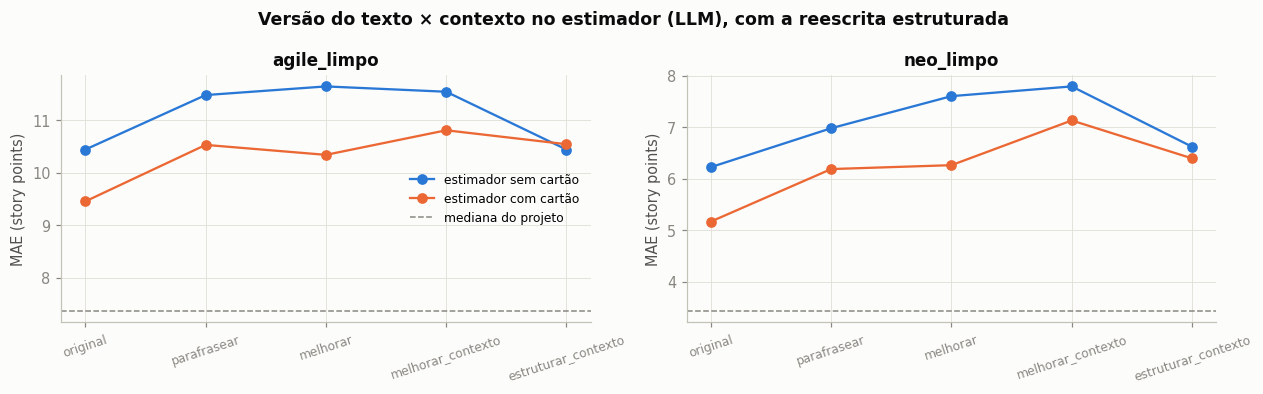

In [15]:
if PARTE2:
    import statsmodels.formula.api as smf
    VERSOES = VERSOES_ANT + [NOVA]
    F = EE[EE.modelo.isin([tag0, tag0 + " + cartão"])].copy()
    F["cartao"] = (F.modelo != tag0).astype(int)
    cont = F.groupby("issue_id").size()
    F = F[F.issue_id.isin(cont[cont == 2 * len(VERSOES)].index)]
    print(f"{F.issue_id.nunique()} issues com as {2 * len(VERSOES)} estimativas")

    tab = (F.pivot_table(index=["dataset", "versao"], columns="cartao", values="abs_err", aggfunc="mean")
             .rename(columns={0: "sem cartão", 1: "com cartão"}))
    tab = tab.reindex([(ds, v) for ds in DATASETS for v in VERSOES if (ds, v) in tab.index])
    tab["Δ do cartão"] = tab["com cartão"] - tab["sem cartão"]
    pm = EE[(EE.modelo == "ProjectMedian") & EE.issue_id.isin(F.issue_id) & (EE.versao == "original")].groupby("dataset").abs_err.mean()
    display(tab.round(3), nome="P2 fatorial MAE")
    print("Mediana do projeto nas mesmas issues:", pm.round(3).to_dict())

    PARES = [("original", 0, "original", 1, "só o contexto no estimador"),
             ("original", 0, "parafrasear", 0, "só mexer no texto (controle)"),
             ("original", 0, "melhorar", 0, "reescrita livre, sem contexto"),
             ("original", 0, "melhorar_contexto", 0, "reescrita livre com contexto"),
             ("original", 0, NOVA, 0, "reescrita estruturada com contexto"),
             ("melhorar_contexto", 0, NOVA, 0, "estruturada × livre (mesma informação)"),
             ("melhorar_contexto", 1, NOVA, 1, "estruturada × livre, com cartão no estimador"),
             ("original", 1, NOVA, 1, "estruturada, com cartão no estimador"),
             ("original", 0, "melhorar_contexto", 1, "tudo junto (livre)"),
             ("original", 0, NOVA, 1, "tudo junto (estruturada)")]
    if EXTRA:
        PARES += [(BASE_E, 0, NOVA, 0, "reescritor novo × llama3 (estimador sem cartão)"),
                  (BASE_E, 1, NOVA, 1, "reescritor novo × llama3 (estimador com cartão)")]
    W2 = F.pivot_table(index=["dataset", "issue_id"], columns=["versao", "cartao"], values="abs_err")
    nome_v = lambda v, c: v + (" + cartão" if c else "")
    rows = []
    for ds in DATASETS + ["ambos"]:
        g = W2 if ds == "ambos" else W2.xs(ds, level="dataset")
        fam = []
        for va, ca, vb, cb, desc in PARES:
            a, b = g[(va, ca)], g[(vb, cb)]
            r = wilcoxon_pareado(a, b); lo, hi = bootstrap_ci(b - a)
            fam.append({"dataset": ds, "contraste": desc, "A": nome_v(va, ca), "B": nome_v(vb, cb),
                        "MAE A": a.mean(), "MAE B": b.mean(), "Δ MAE (B − A)": r["Δ média"],
                        "IC95% inf": lo, "IC95% sup": hi, "p (Wilcoxon)": r["p (Wilcoxon)"], "n": r["n"]})
        fam = pd.DataFrame(fam); fam["p (Holm)"] = holm(fam["p (Wilcoxon)"]).values
        rows.append(fam)
    FAT = pd.concat(rows).set_index(["dataset", "contraste"])
    FAT.to_csv(OUT / "parte2_fatorial_contrastes.csv")
    display(FAT.round(3), nome="P2 fatorial contrastes")
    print("Δ negativo = B errou menos que A.")

    rows = []
    for ds in DATASETS:
        d = F[F.dataset == ds]
        fit = smf.ols("abs_err ~ C(versao, Treatment('original')) * cartao + C(issue_id)", data=d).fit(
            cov_type="cluster", cov_kwds={"groups": pd.factorize(d.issue_id)[0]})
        termos = [t for t in fit.params.index if "versao" in t or t == "cartao"]
        ci = fit.conf_int().loc[termos]
        for t in termos:
            legivel = (t.replace("C(versao, Treatment('original'))[T.", "texto ").replace("]", "")
                        .replace(":cartao", " × cartão").replace("cartao", "cartão"))
            rows.append({"dataset": ds, "termo": legivel, "coef. (SP)": fit.params[t], "IC95% inf": ci.loc[t, 0],
                         "IC95% sup": ci.loc[t, 1], "p": fit.pvalues[t], "n issues": d.issue_id.nunique()})
    REG = pd.DataFrame(rows).set_index(["dataset", "termo"])
    REG.to_csv(OUT / "parte2_fatorial_regressao.csv")
    display(REG.round(3), nome="P2 fatorial regressão")

    fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.8 * len(DATASETS), 3.6))
    for ax, ds in zip(np.atleast_1d(axes), DATASETS):
        if ds not in tab.index.get_level_values(0):
            ax.set_visible(False); continue
        sub = tab.loc[ds]; xs = np.arange(len(sub))
        ax.plot(xs, sub["sem cartão"], "o-", color=COR["s1"], label="estimador sem cartão")
        ax.plot(xs, sub["com cartão"], "o-", color=COR["s2"], label="estimador com cartão")
        if ds in pm:
            ax.axhline(pm[ds], color=COR["muted"], linestyle="--", linewidth=1, label="mediana do projeto")
        ax.set_xticks(xs); ax.set_xticklabels(sub.index, rotation=18, fontsize=8)
        ax.set_ylabel("MAE (story points)"); ax.set_title(ds)
    np.atleast_1d(axes)[0].legend(fontsize=8)
    fig.suptitle("Versão do texto × contexto no estimador (LLM), com a reescrita estruturada", fontweight="bold", color=COR["ink"])
    fig.tight_layout(); salva_fig("parte2_fatorial"); plt.show()

### 2f. As lacunas explicam o erro?

Se faltar informação na issue for o que atrapalha a estimativa, issues com mais campos "Not stated" deveriam ter
erro maior **no texto original**. Cuidado: é uma associação, e as lacunas também se relacionam com o tamanho e o
tipo da issue (como na seção 7 do `analise_jev.ipynb`); por isso a tabela traz também a correlação com o próprio SP.

In [16]:
if PARTE2:
    base_err = EE[EE.versao == "original"].pivot_table(index="issue_id", columns="modelo", values="abs_err")
    LL = L.set_index("issue_id").join(base_err, how="inner")
    rows = []
    for ds in DATASETS:
        d = LL[LL.dataset == ds]
        for alvo in ["sp", *base_err.columns]:
            if d.n_lacunas.nunique() > 1 and len(d) >= 10:
                rho, p = stats.spearmanr(d.n_lacunas, d[alvo])
                rows.append({"dataset": ds, "n_lacunas ×": "SP real" if alvo == "sp" else f"|erro| {alvo} (texto original)",
                             "rho (Spearman)": rho, "p": p, "n": len(d)})
    if rows:
        display(pd.DataFrame(rows).set_index(["dataset", "n_lacunas ×"]).round(3), nome="P2 lacunas x erro")
    rows = []
    for ds in DATASETS:
        d = LL[LL.dataset == ds]
        for c in CAMPOS_LACUNA:
            a, b = d[~d[c]][tag0], d[d[c]][tag0]
            if len(a) >= 5 and len(b) >= 5:
                rows.append({"dataset": ds, "campo": c, "MAE LLM com o campo": a.mean(), "MAE LLM sem o campo": b.mean(),
                             "n com": len(a), "n sem": len(b),
                             "p (Mann-Whitney)": stats.mannwhitneyu(a, b).pvalue})
    if rows:
        display(pd.DataFrame(rows).set_index(["dataset", "campo"]).round(3), nome="P2 erro por campo ausente")

rho (Spearman)     p   n
dataset     n_lacunas ×                                                          
agile_limpo SP real                                              -0.113 0.323  79
            |erro| KNN (texto original)                          -0.026 0.823  79
            |erro| LLM:llama3 (texto original)                    0.136 0.233  79
            |erro| LLM:llama3 + cartão (texto original)           0.052 0.646  79
            |erro| ProjectMedian (texto original)                -0.066 0.561  79
            |erro| XGBoost (texto original)                       0.000 0.997  79
neo_limpo   SP real                                               0.153 0.274  53
            |erro| KNN (texto original)                          -0.070 0.618  53
            |erro| LLM:llama3 (texto original)                    0.254 0.066  53
            |erro| LLM:llama3 + cartão (texto original)           0.271 0.050  53
            |erro| ProjectMedian (texto original)                 0.128 0.360  53
            |erro| XGBoost (texto original)                       0.123 0.380  53

MAE LLM com o campo  MAE LLM sem o campo  n com  n sem  p (Mann-Whitney)
dataset     campo                                                                                        
agile_limpo Affected components               10.729                8.222     70      9             0.149
            Acceptance criteria                5.143               10.958      7     72             0.417
neo_limpo   Acceptance criteria                4.417                6.756     12     41             0.111

### 2g. Reescrita × estimador por analogia (a pergunta central com um estimador competente)

Até aqui, o efeito da reescrita foi medido com o ZS1, que erra o dobro da mediana do projeto. Pode ser que melhorar
o texto só ajude quando o estimador já sabe a escala do time. Aqui cada versão do texto (original, parafrasear,
melhorar, melhorar_contexto e a estruturada) é estimada pelo **few-shot com os exemplos mais parecidos do mesmo
projeto** (o mesmo prompt do `30_run_llm.py --template FS1 --shots-from similar_same_project`).
- A busca dos exemplos usa o texto da versão: um texto melhor pode achar exemplos mais parecidos (é um dos
  caminhos pelos quais melhorar a issue ajudaria). Os exemplos em si são issues originais do treino.
- O controle continua sendo o **parafrasear**: o ganho atribuível à melhoria é melhorar × parafrasear.
- Custo: ~5 × 132 chamadas ao LLM estimador (as que já existem no `30_run_llm.py` são reaproveitadas pelo hash
  do prompt). Cache: `llm_{modelo}_{versão}__fs.jsonl`.

In [17]:
if PARTE2 and RODAR_REESCRITA_X_ANALOGIA:
    from types import SimpleNamespace
    from see.prompts import few_shot
    llm30 = load_script("30_run_llm.py")            # OPTS no padrão: TF-IDF, 2 a 4 exemplos (igual ao comando 2)

    def le_rew(cond):
        arqs = sorted(EXP.glob(f"rewrites_{cond}_llama3_*.jsonl"), key=lambda f: f.stat().st_mtime)
        return done_ids(arqs[-1]) if arqs else {}
    VFS = {"original": O}
    for cond in ["parafrasear", "melhorar", "melhorar_contexto"]:
        rw = le_rew(cond)
        v = O[O.issue_id.isin(rw)].copy()
        v["title"] = v.issue_id.map(lambda i: rw[i]["title"]); v["description"] = v.issue_id.map(lambda i: rw[i]["description"])
        VFS[cond] = v
    VFS.update({k: VERS[k] for k in VERS if k != "original"})          # estruturada(s)
    ids_fs = set(O.issue_id)
    for v in VFS.values():
        ids_fs &= set(v.issue_id)
    ids_fs = sorted(ids_fs)
    print(f"{len(ids_fs)} issues com todas as versões: {list(VFS)}")

    # respostas já dadas pelo 30_run_llm.py (mesmo prompt = mesmo hash): não chama de novo
    reuso = {}
    for ds in DATASETS:
        f = config.LLM_RAW / ds / "within_fewshot_simproj" / f"{SLUG_EST}__FS1__similar_same_project.jsonl"
        if f.exists():
            for line in f.read_text(encoding="utf-8").splitlines():
                if line.strip():
                    r = json.loads(line)
                    if not r.get("error"):
                        reuso[r["prompt_sha1"]] = r
    DFS = {ds: load_merged(ds) for ds in DATASETS}
    rows = []
    for n, v in VFS.items():
        path = EXP / f"llm_{SLUG_EST}_{n}__fs.jsonl"
        done = {}
        if path.exists():
            for line in path.read_text(encoding="utf-8").splitlines():
                if line.strip():
                    r = json.loads(line); done[r["issue_id"]] = r
        vv = v.set_index("issue_id").loc[ids_fs]
        todo = [i for i in ids_fs if i not in done]
        print(f"FS parecidos / {n}: {len(done)} prontas, {len(todo)} a fazer")
        with open(path, "a", encoding="utf-8") as f:
            for i in todo:
                r = vv.loc[i]
                row = SimpleNamespace(issue_id=i, project=r.project, title=r.title, description=r.description)
                ex = llm30.pick_examples(DFS[r.dataset], row, "similar_same_project", 2000 // 3)
                prompt = few_shot("FS1", clean_light(r.title), truncate(clean_light(r.description), 2000), ex)
                sha = hashlib.sha1(prompt.encode()).hexdigest()
                if sha in reuso:
                    rec = {"issue_id": i, "y_pred": reuso[sha]["parsed"], "raw": reuso[sha]["response"][:200], "reuso": True}
                else:
                    try:
                        text, _, _ = call_with_retry(est_client, prompt)
                        rec = {"issue_id": i, "y_pred": parse_estimate(text), "raw": text[:200]}
                    except Exception as e:
                        rec = {"issue_id": i, "y_pred": None, "error": str(e)[:200]}
                f.write(json.dumps(rec) + "\n"); f.flush(); done[i] = rec
        rows.append(pd.DataFrame({"issue_id": ids_fs, "versao": n, "dataset": vv.dataset.values,
                                  "y_pred": [done[i].get("y_pred") for i in ids_fs]}))
    FSV = pd.concat(rows, ignore_index=True)
    FSV["y_pred"] = pd.to_numeric(FSV.y_pred, errors="coerce")
    fora = FSV.y_pred.notna() & na_faixa(FSV.y_pred, FSV.dataset).isna()
    FSV["y_pred"] = na_faixa(FSV.y_pred, FSV.dataset)
    inval = FSV.y_pred.isna()
    if inval.any():
        print(f"{int(inval.sum())} estimativas inválidas ({int(fora.sum())} fora da faixa) → mediana do treino")
        FSV.loc[inval, "y_pred"] = FSV.loc[inval, "dataset"].map(TRAIN_MED)
    FSV = FSV.merge(O[["issue_id", "sp", "project"]], on="issue_id")
    FSV["abs_err"] = (FSV.sp - FSV.y_pred).abs()
    W3 = FSV.pivot_table(index=["dataset", "issue_id"], columns="versao", values="abs_err")
    pm3 = EE[(EE.modelo == "ProjectMedian") & (EE.versao == "original")].set_index("issue_id").abs_err
    zs3 = EE[(EE.modelo == tag0) & (EE.versao == "original")].set_index("issue_id").abs_err

    tab3 = W3.groupby(level="dataset").mean().T.reindex(list(VFS))
    tab3.loc["(ref.) mediana do projeto"] = [pm3.reindex(W3.xs(ds, level="dataset").index).mean() for ds in tab3.columns]
    tab3.loc["(ref.) ZS1, texto original"] = [zs3.reindex(W3.xs(ds, level="dataset").index).mean() for ds in tab3.columns]
    display(tab3.round(3), nome="P2g MAE por versão (analogia)")

    PARES3 = [("original", "parafrasear", "só mexer no texto (controle)"),
              ("original", "melhorar", "melhorar"),
              ("parafrasear", "melhorar", "melhorar × controle"),
              ("original", "melhorar_contexto", "melhorar com contexto"),
              ("parafrasear", "melhorar_contexto", "melhorar com contexto × controle")]
    PARES3 += [("original", k, f"{k}") for k in VFS if k.startswith(BASE_E)]
    PARES3 += [("parafrasear", k, f"{k} × controle") for k in VFS if k.startswith(BASE_E)]
    rows = []
    for ds in DATASETS + ["ambos"]:
        g = W3 if ds == "ambos" else W3.xs(ds, level="dataset")
        fam = []
        for a, b, desc in PARES3:
            r = wilcoxon_pareado(g[a], g[b]); lo, hi = bootstrap_ci(g[b] - g[a])
            fam.append({"dataset": ds, "contraste": desc, "A": a, "B": b, "MAE A": g[a].mean(), "MAE B": g[b].mean(),
                        "Δ MAE (B − A)": r["Δ média"], "IC95% inf": lo, "IC95% sup": hi,
                        "p (Wilcoxon)": r["p (Wilcoxon)"], "n": r["n"]})
        fam = pd.DataFrame(fam); fam["p (Holm)"] = holm(fam["p (Wilcoxon)"]).values; rows.append(fam)
    FS3 = pd.concat(rows).set_index(["dataset", "contraste"])
    FS3.to_csv(OUT / "parte2g_reescrita_x_analogia.csv")
    display(FS3.round(3), nome="P2g contrastes (analogia)")
    print("Δ negativo = a versão B errou menos. Se 'melhorar × controle' ficar negativo aqui (e não com o ZS1),")
    print("a melhoria do texto só ajuda quando o estimador conhece a escala do time.")
elif PARTE2:
    print("RODAR_REESCRITA_X_ANALOGIA = False: seção 2g pulada.")

132 issues com todas as versões: ['original', 'parafrasear', 'melhorar', 'melhorar_contexto', 'estruturar_contexto']
FS parecidos / original: 132 prontas, 0 a fazer
FS parecidos / parafrasear: 132 prontas, 0 a fazer
FS parecidos / melhorar: 132 prontas, 0 a fazer
FS parecidos / melhorar_contexto: 132 prontas, 0 a fazer
FS parecidos / estruturar_contexto: 132 prontas, 0 a fazer
1 estimativas inválidas (1 fora da faixa) → mediana do treino


dataset,agile_limpo,neo_limpo
versao,,
original,6.127,3.698
parafrasear,8.063,2.811
melhorar,8.038,3.321
melhorar_contexto,7.418,3.396
estruturar_contexto,6.785,3.566
(ref.) mediana do projeto,7.367,3.434
"(ref.) ZS1, texto original",10.443,6.226


A                    B  MAE A  MAE B  Δ MAE (B − A)  IC95% inf  IC95% sup  p (Wilcoxon)    n  p (Holm)
dataset     contraste                                                                                                                                         
agile_limpo só mexer no texto (controle)         original          parafrasear  6.127  8.063          1.937     -0.026      4.950         0.478   79     1.000
            melhorar                             original             melhorar  6.127  8.038          1.911      0.089      4.785         0.353   79     1.000
            melhorar × controle               parafrasear             melhorar  8.063  8.038         -0.025     -0.747      0.696         0.892   79     1.000
            melhorar com contexto                original    melhorar_contexto  6.127  7.418          1.291     -0.810      4.114         0.485   79     1.000
            melhorar com contexto × controle  parafrasear    melhorar_contexto  8.063  7.418         -0.646     -2.038      0.582         0.756   79     1.000
            estruturar_contexto                  original  estruturar_contexto  6.127  6.785          0.658     -1.582      3.684         0.844   79     1.000
            estruturar_contexto × controle    parafrasear  estruturar_contexto  8.063  6.785         -1.278     -3.545      0.418         0.446   79     1.000
neo_limpo   só mexer no texto (controle)         original          parafrasear  3.698  2.811         -0.887     -1.604     -0.208         0.015   53     0.105
            melhorar                             original             melhorar  3.698  3.321         -0.377     -1.264      0.585         0.172   53     0.690
            melhorar × controle               parafrasear             melhorar  2.811  3.321          0.509     -0.264      1.377         0.316   53     0.949
            melhorar com contexto                original    melhorar_contexto  3.698  3.396         -0.302     -0.981      0.396         0.436   53     0.949
            melhorar com contexto × controle  parafrasear    melhorar_contexto  2.811  3.396          0.585     -0.094      1.321         0.085   53     0.425
            estruturar_contexto                  original  estruturar_contexto  3.698  3.566         -0.132     -0.868      0.604         0.599   53     0.949
            estruturar_contexto × controle    parafrasear  estruturar_contexto  2.811  3.566          0.755      0.000      1.566         0.055   53     0.332
ambos       só mexer no texto (controle)         original          parafrasear  5.152  5.955          0.803     -0.432      2.591         0.416  132     1.000
            melhorar                             original             melhorar  5.152  6.144          0.992     -0.182      2.674         0.851  132     1.000
            melhorar × controle               parafrasear             melhorar  5.955  6.144          0.189     -0.356      0.735         0.513  132     1.000
            melhorar com contexto                original    melhorar_contexto  5.152  5.803          0.652     -0.637      2.296         0.925  132     1.000
            melhorar com contexto × controle  parafrasear    melhorar_contexto  5.955  5.803         -0.152     -1.038      0.614         0.512  132     1.000
            estruturar_contexto                  original  estruturar_contexto  5.152  5.492          0.341     -1.061      2.136         0.908  132     1.000
            estruturar_contexto × controle    parafrasear  estruturar_contexto  5.955  5.492         -0.462     -1.849      0.637         0.612  132     1.000

Δ negativo = a versão B errou menos. Se 'melhorar × controle' ficar negativo aqui (e não com o ZS1),
a melhoria do texto só ajuda quando o estimador conhece a escala do time.


## Salvar

Grava todas as tabelas num Excel (`results/analise_extensoes/relatorio_extensoes.xlsx`); as figuras já ficaram em
`results/analise_extensoes/figuras/`.

In [18]:
xlsx = OUT / "relatorio_extensoes.xlsx"
with pd.ExcelWriter(xlsx) as w:
    usados = set()
    for nome, t in TABELAS.items():
        aba = re.sub(r"[\[\]\*\?/\\:]", "", nome)[:31]
        k = 2
        while aba in usados:
            aba = f"{aba[:28]}_{k}"; k += 1
        usados.add(aba)
        t.to_excel(w, sheet_name=aba)
print(f"{len(TABELAS)} tabelas em {xlsx.relative_to(ROOT)}")

23 tabelas em results\analise_extensoes\relatorio_extensoes.xlsx
